In [ ]:
import itertools

import altair as alt
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mendeleev.fetch import fetch_table
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from wigglystuff import CellTour, ParallelCoordinates, SortableList, TangleSlider


In [ ]:
import os

# export.sh sets AIDS_EXPAND=1, so the PDF and ipynb show every "Go deeper" box opened.
EXPAND_DETAILS = os.environ.get("AIDS_EXPAND") == "1"


def deeper(items):
    """Folded boxes (mo.accordion) in the live notebook; open sections in static exports."""
    if not EXPAND_DETAILS:
        return mo.accordion(items)
    return mo.vstack([part for title, body in items.items() for part in (mo.md(f"#### {title}"), body)])

## Part 0 · The data

The file has one row for each of the 118 elements. We use these 8 numeric features:

| Feature | Unit | Meaning |
|:---|:---|:---|
| AtomicMass | u | mass of one atom |
| Electronegativity | Pauling scale | how strongly the atom pulls shared electrons |
| AtomicRadius | pm | size of the atom |
| IonizationEnergy | eV | energy to remove one electron |
| ElectronAffinity | eV | energy released when the atom takes one extra electron |
| MeltingPoint | K | temperature where the solid melts |
| BoilingPoint | K | temperature where the liquid boils |
| Density | g/cm³ | mass per volume |

The data has three problems: many heavy elements have **blanks**, `YearDiscovered` contains the text **"Ancient"**, and `StandardState` contains values such as **"Expected to be a Solid"**. We handle each problem below.

In [ ]:
df = pd.read_csv("data/PubChemElements_all.csv")
df

,AtomicNumber,Symbol,Name,AtomicMass,CPKHexColor,ElectronConfiguration,Electronegativity,AtomicRadius,IonizationEnergy,ElectronAffinity,OxidationStates,StandardState,MeltingPoint,BoilingPoint,Density,GroupBlock,YearDiscovered
0,1,H,Hydrogen,1.008000,FFFFFF,1s1,2.20,120.0,13.598,0.754,"+1, -1",Gas,13.81,20.28,0.000090,Nonmetal,1766
1,2,He,Helium,4.002600,D9FFFF,1s2,NaN,140.0,24.587,NaN,0,Gas,0.95,4.22,0.000179,Noble gas,1868
2,3,Li,Lithium,7.000000,CC80FF,[He]2s1,0.98,182.0,5.392,0.618,+1,Solid,453.65,1615.00,0.534000,Alkali metal,1817
3,4,Be,Beryllium,9.012183,C2FF00,[He]2s2,1.57,153.0,9.323,NaN,+2,Solid,1560.00,2744.00,1.850000,Alkaline earth metal,1798
4,5,B,Boron,10.810000,FFB5B5,[He]2s2 2p1,2.04,192.0,8.298,0.277,+3,Solid,2348.00,4273.00,2.370000,Metalloid,1808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,114,Fl,Flerovium,290.192000,NaN,[Rn]7s2 7p2 5f14 6d10 (predicted),NaN,NaN,NaN,NaN,"6, 4,2, 1, 0",Expected to be a Solid,NaN,NaN,NaN,Post-transition metal,1998
114,115,Mc,Moscovium,290.196000,NaN,[Rn]7s2 7p3 5f14 6d10 (predicted),NaN,NaN,NaN,NaN,"3, 1",Expected to be a Solid,NaN,NaN,NaN,Post-transition metal,2003
115,116,Lv,Livermorium,293.205000,NaN,[Rn]7s2 7p4 5f14 6d10 (predicted),NaN,NaN,NaN,NaN,"+4, +2, -2",Expected to be a Solid,NaN,NaN,NaN,Post-transition metal,2000
116,117,Ts,Tennessine,294.211000,NaN,[Rn]7s2 7p5 5f14 6d10 (predicted),NaN,NaN,NaN,NaN,"+5, +3, +1, -1",Expected to be a Solid,NaN,NaN,NaN,Halogen,2010


,missing,missing_%
ElectronAffinity,61,51.7
BoilingPoint,25,21.2
Electronegativity,23,19.5
Density,22,18.6
AtomicRadius,19,16.1
IonizationEnergy,16,13.6
MeltingPoint,15,12.7
AtomicMass,0,0.0

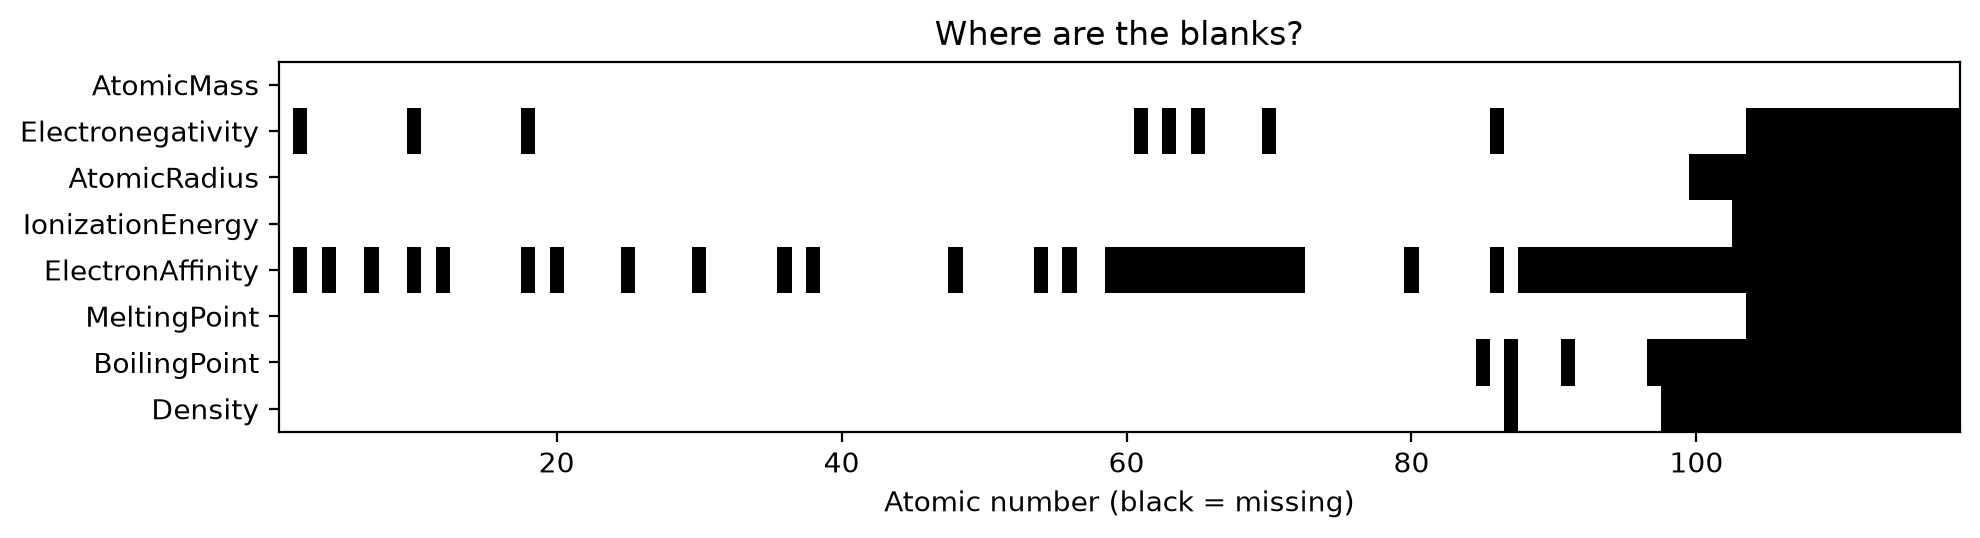

In [ ]:
FEATURES = [
    "AtomicMass",
    "Electronegativity",
    "AtomicRadius",
    "IonizationEnergy",
    "ElectronAffinity",
    "MeltingPoint",
    "BoilingPoint",
    "Density",
]

missing_summary = pd.DataFrame(
    {
        "missing": df[FEATURES].isna().sum(),
        "missing_%": (100 * df[FEATURES].isna().mean()).round(1),
    }
).sort_values("missing", ascending=False)

_fig, _ax = plt.subplots(figsize=(10, 2.8))
_ax.imshow(
    df[FEATURES].isna().T.to_numpy(),
    aspect="auto",
    cmap="Greys",
    interpolation="nearest",
    extent=(0.5, len(df) + 0.5, len(FEATURES) - 0.5, -0.5),
)
_ax.set_yticks(range(len(FEATURES)), FEATURES)
_ax.set_xlabel("Atomic number (black = missing)")
_ax.set_title("Where are the blanks?")
_fig.tight_layout()

_bad_years = sorted(set(df["YearDiscovered"][pd.to_numeric(df["YearDiscovered"], errors="coerce").isna()]))
mo.vstack(
    [
        mo.md(
            f"Only **{df[FEATURES].notna().all(axis=1).sum()} of {len(df)}** elements have all 8 features. "
            "Most blanks are in the heavy elements (right side). Electron affinity has the most blanks."
        ),
        _fig,
        missing_summary,
        mo.md(
            f"- Text in `YearDiscovered`: `{_bad_years}` ({df['YearDiscovered'].isin(_bad_years).sum()} elements)\n"
            f"- Values of `StandardState`: `{df['StandardState'].value_counts().to_dict()}`"
        ),
    ]
)

### What we do with each problem

| Problem | What we do | Why |
|:---|:---|:---|
| `YearDiscovered` = "Ancient" | Set a flag `DiscoveredAncient = True`. Leave the year empty. | "Ancient" is a fact (the element was known in old times). It is not a missing value. |
| `StandardState` = "Expected to be a Solid" | Keep "Solid". Set a flag `StatePredicted = True`. | The state of a man-made element is a prediction, not a measurement. |
| Elements 100–118 (Fm–Og) | Remove them. | Only 1 to 4 of the 8 features are known. Filling in the rest would invent the element. |
| No electron affinity for noble gases, group 2, Zn, Cd, Hg, N and Mn | Set it to 0. | These atoms do not hold an extra electron, so the true value is 0 or below. |
| All other blanks | Fill them from the 5 most similar elements (KNN imputation). | Similar elements have similar values. We check these guesses against a reference library below. |
| Very different units | Rescale each feature to mean 0 and spread 1 (z-score). | Without this, temperatures in kelvin (up to 5869) hide everything else. |

`StandardState` and `GroupBlock` are text labels. They are **not** inputs to PCA or k-means. We use `GroupBlock` and the table position only to **check** the clusters in Q2.

In [ ]:
def periodic_position(z: int) -> tuple[int, int]:
    """(row, column) of element z in the 18-column periodic table.

    Rows 1-7 are the periods. La and Ac sit in group 3. Ce-Lu and Th-Lr go to
    the detached f-block rows 9 and 10 (columns 4-17), as in the usual printed table.
    """
    ends = [2, 10, 18, 36, 54, 86, 118]
    period = next(p for p, end in enumerate(ends, start=1) if z <= end)
    i = z - ([0] + ends)[period - 1]  # 1-based position inside the period
    if period == 1:
        return 1, 1 if z == 1 else 18
    if period <= 3:
        return period, i if i <= 2 else i + 10
    if period <= 5 or i <= 3:
        return period, i
    if i <= 17:
        return period + 3, i  # f-block row
    return period, i - 14


assert periodic_position(1) == (1, 1) and periodic_position(2) == (1, 18)
assert periodic_position(13) == (3, 13) and periodic_position(26) == (4, 8)
assert periodic_position(57) == (6, 3) and periodic_position(58) == (9, 4)
assert periodic_position(71) == (9, 17) and periodic_position(72) == (6, 4)
assert periodic_position(86) == (6, 18) and periodic_position(103) == (10, 17)

In [ ]:
clean = df.copy()

# YearDiscovered: "Ancient" is a fact (known since antiquity), not a missing value.
clean["DiscoveredAncient"] = clean["YearDiscovered"].eq("Ancient")
clean["YearDiscovered"] = pd.to_numeric(
    clean["YearDiscovered"].mask(clean["DiscoveredAncient"]), errors="raise"
).astype("Int64")

# StandardState: "Expected to be a Solid" is a prediction for a man-made element.
clean["StatePredicted"] = clean["StandardState"].str.startswith("Expected to be")
clean["StandardState"] = clean["StandardState"].str.removeprefix("Expected to be a ")

# Position in the periodic table. Used only to check the clusters in Q2.
clean[["Row", "Column"]] = pd.DataFrame(
    [periodic_position(z) for z in clean["AtomicNumber"]], index=clean.index
)
clean["Period"] = clean["Row"].where(clean["Row"] <= 7, clean["Row"] - 3)
clean["Group"] = clean["Column"].astype(str).where(clean["Row"] <= 7, "f-block")

# Cross-check the layout against the mendeleev reference library, and take the s/p/d/f block from it.
_ref = fetch_table("elements").set_index("atomic_number").loc[clean["AtomicNumber"]]
assert (_ref["period"].to_numpy() == clean["Period"].to_numpy()).all()
assert (
    _ref["group_id"].fillna(-1).to_numpy()
    == pd.to_numeric(clean["Group"], errors="coerce").fillna(-1).to_numpy()
).all()
clean["Block"] = _ref["block"].to_numpy()

mo.vstack(
    [
        mo.md(
            f"- Known since ancient times ({clean['DiscoveredAncient'].sum()}): {', '.join(clean['Symbol'][clean['DiscoveredAncient']])}\n"
            f"- Predicted state ({clean['StatePredicted'].sum()}): {', '.join(clean['Symbol'][clean['StatePredicted']])}\n"
            f"- `StandardState` after cleaning: `{clean['StandardState'].value_counts().to_dict()}`\n"
            f"- Our period and group for every element match the **mendeleev** library."
        ),
        mo.md("**The rows we changed** (ancient or predicted state):"),
        clean.loc[
            clean["DiscoveredAncient"] | clean["StatePredicted"],
            ["Symbol", "YearDiscovered", "DiscoveredAncient", "StandardState", "StatePredicted", "Block", "Period", "Group"],
        ],
    ]
)

,Symbol,YearDiscovered,DiscoveredAncient,StandardState,StatePredicted,Block,Period,Group
5,C,<NA>,True,Solid,False,p,2,14
12,Al,<NA>,True,Solid,False,p,3,13
15,S,<NA>,True,Solid,False,p,3,16
19,Ca,<NA>,True,Solid,False,s,4,2
25,Fe,<NA>,True,Solid,False,d,4,8
...,...,...,...,...,...,...,...,...
113,Fl,1998,False,Solid,True,p,7,14
114,Mc,2003,False,Solid,True,p,7,15
115,Lv,2000,False,Solid,True,p,7,16
116,Ts,2010,False,Solid,True,p,7,17


In [ ]:
MIN_OBSERVED = 5  # keep an element only if at least 5 of the 8 features are measured

_n_observed = clean[FEATURES].notna().sum(axis=1)
dropped_symbols = clean.loc[_n_observed < MIN_OBSERVED, "Symbol"].tolist()
elements = clean.loc[_n_observed >= MIN_OBSERVED].reset_index(drop=True)

# ElectronAffinity: a blank means the atom does not hold an extra electron (EA <= 0).
# This holds for noble gases, group 2, group 12, N and Mn, so we use 0.
_unbound_anion = elements["GroupBlock"].isin(["Noble gas", "Alkaline earth metal"]) | elements[
    "Symbol"
].isin(["N", "Mn", "Zn", "Cd", "Hg"])
_fill_zero = _unbound_anion & elements["ElectronAffinity"].isna()
ea_set_zero = elements.loc[_fill_zero, "Symbol"].tolist()
elements.loc[_fill_zero, "ElectronAffinity"] = 0.0

# All other blanks: KNN imputation on rescaled features. AtomicNumber is NOT used,
# so the table position cannot leak into Q2.
imputed_mask = elements[FEATURES].isna().set_axis(elements["Symbol"])
_scaler = StandardScaler()
_filled = KNNImputer(n_neighbors=5, weights="distance").fit_transform(
    _scaler.fit_transform(elements[FEATURES])
)
X = pd.DataFrame(_scaler.inverse_transform(_filled), columns=FEATURES, index=elements["Symbol"])

mo.vstack(
    [
        mo.md(
            f"- Removed **{len(dropped_symbols)}** elements with fewer than {MIN_OBSERVED} known features: {', '.join(dropped_symbols)}.\n"
            f"- Kept **{len(elements)} elements** ({elements['Symbol'].iloc[0]} to {elements['Symbol'].iloc[-1]}).\n"
            f"- Set electron affinity to 0 for {len(ea_set_zero)} elements: {', '.join(ea_set_zero)}.\n"
            f"- Filled **{int(imputed_mask.to_numpy().sum())}** other blanks with KNN."
        ),
        deeper({"Show the filled-in values": X.where(imputed_mask).dropna(how="all").round(3)}),
    ]
)

,AtomicMass,Electronegativity,AtomicRadius,IonizationEnergy,ElectronAffinity,MeltingPoint,BoilingPoint,Density
Symbol,,,,,,,,
He,NaN,3.090,NaN,NaN,NaN,NaN,NaN,NaN
Ne,NaN,2.807,NaN,NaN,NaN,NaN,NaN,NaN
Ar,NaN,2.893,NaN,NaN,NaN,NaN,NaN,NaN
Pr,NaN,NaN,NaN,NaN,0.447,NaN,NaN,NaN
Nd,NaN,NaN,NaN,NaN,0.386,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
Am,NaN,NaN,NaN,NaN,0.424,NaN,NaN,NaN
Cm,NaN,NaN,NaN,NaN,0.432,NaN,NaN,NaN
Bk,NaN,NaN,NaN,NaN,0.426,NaN,3117.563,NaN


In [ ]:
# How good are the filled-in values? Compare them with the mendeleev reference library.
_el = fetch_table("elements")
_bp = fetch_table("phasetransitions").groupby("atomic_number")["boiling_point"].max()
reference = pd.DataFrame(
    {
        "Electronegativity": _el["en_pauling"].to_numpy(),
        "ElectronAffinity": _el["electron_affinity"].to_numpy(),
        "Density": _el["density"].to_numpy(),
        "BoilingPoint": _el["atomic_number"].map(_bp).to_numpy(),
    },
    index=_el["symbol"],
)

_cells = imputed_mask.stack()
imputation_check = pd.DataFrame(
    [
        {
            "element": s,
            "feature": f,
            "our guess (KNN)": X.loc[s, f],
            "reference (mendeleev)": reference.loc[s, f],
        }
        for s, f in _cells[_cells].index
        if f in reference.columns and pd.notna(reference.loc[s, f])
    ]
)
imputation_check["error / feature spread"] = (
    (imputation_check["our guess (KNN)"] - imputation_check["reference (mendeleev)"]).abs()
    / imputation_check["feature"].map(X.std())
)

_negative_ea = [s for s in ea_set_zero if reference.loc[s, "ElectronAffinity"] < 0]
mo.vstack(
    [
        mo.md(
            f"""
### Check: how good are the filled-in values?

The **mendeleev** library has reference values for {len(imputation_check)} of the {int(imputed_mask.to_numpy().sum())} values we filled in.
The typical (median) error is **{imputation_check['error / feature spread'].median():.2f}** of the feature's spread (1.0 = one standard deviation).
So the guesses are **rough**. Most of the larger errors are in the electron affinity of the lanthanides, where even the reference values are uncertain (many are calculated, not measured).
This is one reason we test later if the clusters change when we fill the blanks in other ways, or leave out all filled values. They do not change much.

mendeleev also lists a **negative** electron affinity for {', '.join(_negative_ea)}. A negative value means the atom does not hold the extra electron. This supports our choice of 0 for these elements.
"""
        ),
        deeper({"Show the comparison": imputation_check.round(3)}),
    ]
)

,element,feature,our guess (KNN),reference (mendeleev),error / feature spread
0,Pr,ElectronAffinity,0.447,0.962,0.650
1,Nd,ElectronAffinity,0.386,1.916,1.931
2,Eu,ElectronAffinity,0.383,0.864,0.607
3,Tb,ElectronAffinity,0.573,1.165,0.747
4,Dy,ElectronAffinity,0.317,0.352,0.044
...,...,...,...,...,...
8,Hf,ElectronAffinity,0.629,0.014,0.776
9,Fr,Density,3.844,1.870,0.333
10,Ac,ElectronAffinity,0.265,0.350,0.108
11,Cf,Density,15.831,15.100,0.123


## Q1 · Which features matter most?

### The idea in plain words

PCA finds new **directions** in the data. Each direction is a mix of the 8 features.
The first direction holds the most variation between elements, the second holds the next most, and so on.

The **weights** in the mix tell us how much each feature counts in a direction.
If a feature has small weights in all the important directions, it adds little. We can remove it and lose almost nothing.

### The method of Song, Guo & Mei (2010)

In [ ]:
mo.mermaid(
            """
graph LR
  A["8 features<br/>(rescaled)"] --> B["covariance<br/>matrix"]
  B --> C["eigenvectors<br/>V1 … V8"]
  C --> D["keep the<br/>top m"]
  D --> E["score each feature<br/>c_j = Σ |V_pj|"]
  E --> F["sort →<br/>ranking"]
"""
        )

<marimo-mermaid data-diagram='"\ngraph LR\n A[\"8 features\u003cbr/\u003e(rescaled)\"] --\u003e B[\"covariance\u003cbr/\u003ematrix\"]\n B --\u003e C[\"eigenvectors\u003cbr/\u003eV1 … V8\"]\n C --\u003e D[\"keep the\u003cbr/\u003etop m\"]\n D --\u003e E[\"score each feature\u003cbr/\u003ec_j = Σ |V_pj|\"]\n E --\u003e F[\"sort →\u003cbr/\u003eranking\"]\n"'>

1. Compute the covariance matrix of the data. Find its eigenvectors (directions) and eigenvalues (how much variation each direction holds).
2. Keep the $m$ eigenvectors with the largest eigenvalues: $V_1, \dots, V_m$.
3. Give each feature $j$ a score: the sum of its absolute weights in these directions,
$$c_j = \sum_{p=1}^{m} |V_{pj}|$$
4. Sort the scores from high to low. This order is the ranking. To keep $n$ features, keep the top $n$.

The authors tested the method on face photos, where each pixel is one feature. With a nearest-neighbour classifier, 600 of 2000 pixels gave a **lower** error than all pixels (AR faces: 0.505 → 0.319).

*Reference: F. Song, Z. Guo, D. Mei, "Feature selection using principal component analysis", ICSEM 2010, pp. 27–30, doi:10.1109/ICSEM.2010.14.*

**Two choices we must make.** The paper does not say how to pick $m$. We use the Kaiser rule: keep directions with eigenvalue > 1. The paper also does not rescale the data. Our features have very different units, so we rescale them first (we show why in a "Go deeper" box below).

In [ ]:
guess = mo.ui.anywidget(SortableList(value=sorted(FEATURES), label="Most important at the top"))
mo.vstack(
    [
        mo.md(
            "### Before you look: make a guess\n"
            "Which features do you think matter most? **Drag** them into order (top = most important). "
            "We compare your guess with the PCA answer below."
        ),
        guess,
    ]
)

Before you look: make a guess 
 Which features do you think matter most? Drag them into order (top = most important). We compare your guess with the PCA answer below.

In [ ]:
X_std = StandardScaler().fit_transform(X)

# Step 1: covariance matrix of the rescaled data and all eigenpairs (written out, not a black box).
_cov = np.cov(X_std, rowvar=False)
_vals, _vecs = np.linalg.eigh(_cov)
_order = np.argsort(_vals)[::-1]
eigenvalues = _vals[_order]
eigenvectors = _vecs[:, _order]  # column p is direction V_p, row j is feature j
explained = eigenvalues / eigenvalues.sum()

# Cross-check against scikit-learn (the directions agree up to sign).
_pca = PCA().fit(X_std)
assert np.allclose(eigenvalues, _pca.explained_variance_)
assert np.allclose(np.abs(eigenvectors), np.abs(_pca.components_.T))

m_kaiser = int((eigenvalues > 1).sum())
m_90 = int(np.searchsorted(np.cumsum(explained), 0.90) + 1)

deeper(
    {
        "Show the eigenvalue table": pd.DataFrame(
            {
                "eigenvalue": eigenvalues,
                "explained_%": 100 * explained,
                "cumulative_%": 100 * np.cumsum(explained),
            },
            index=[f"PC{p}" for p in range(1, len(FEATURES) + 1)],
        ).round(3)
    }
)

,eigenvalue,explained_%,cumulative_%
PC1,3.741,46.292,46.292
PC2,1.863,23.050,69.342
PC3,1.183,14.632,83.974
PC4,0.683,8.450,92.425
PC5,0.335,4.145,96.569
PC6,0.101,1.251,97.821
PC7,0.097,1.194,99.015
PC8,0.080,0.985,100.000


The first 3 directions have an eigenvalue above 1 (blue bars). Together they hold 84% of the variation. So our default is m = 3 . In the right chart, dark red or dark blue means a big weight. The sign does not matter, only the size.
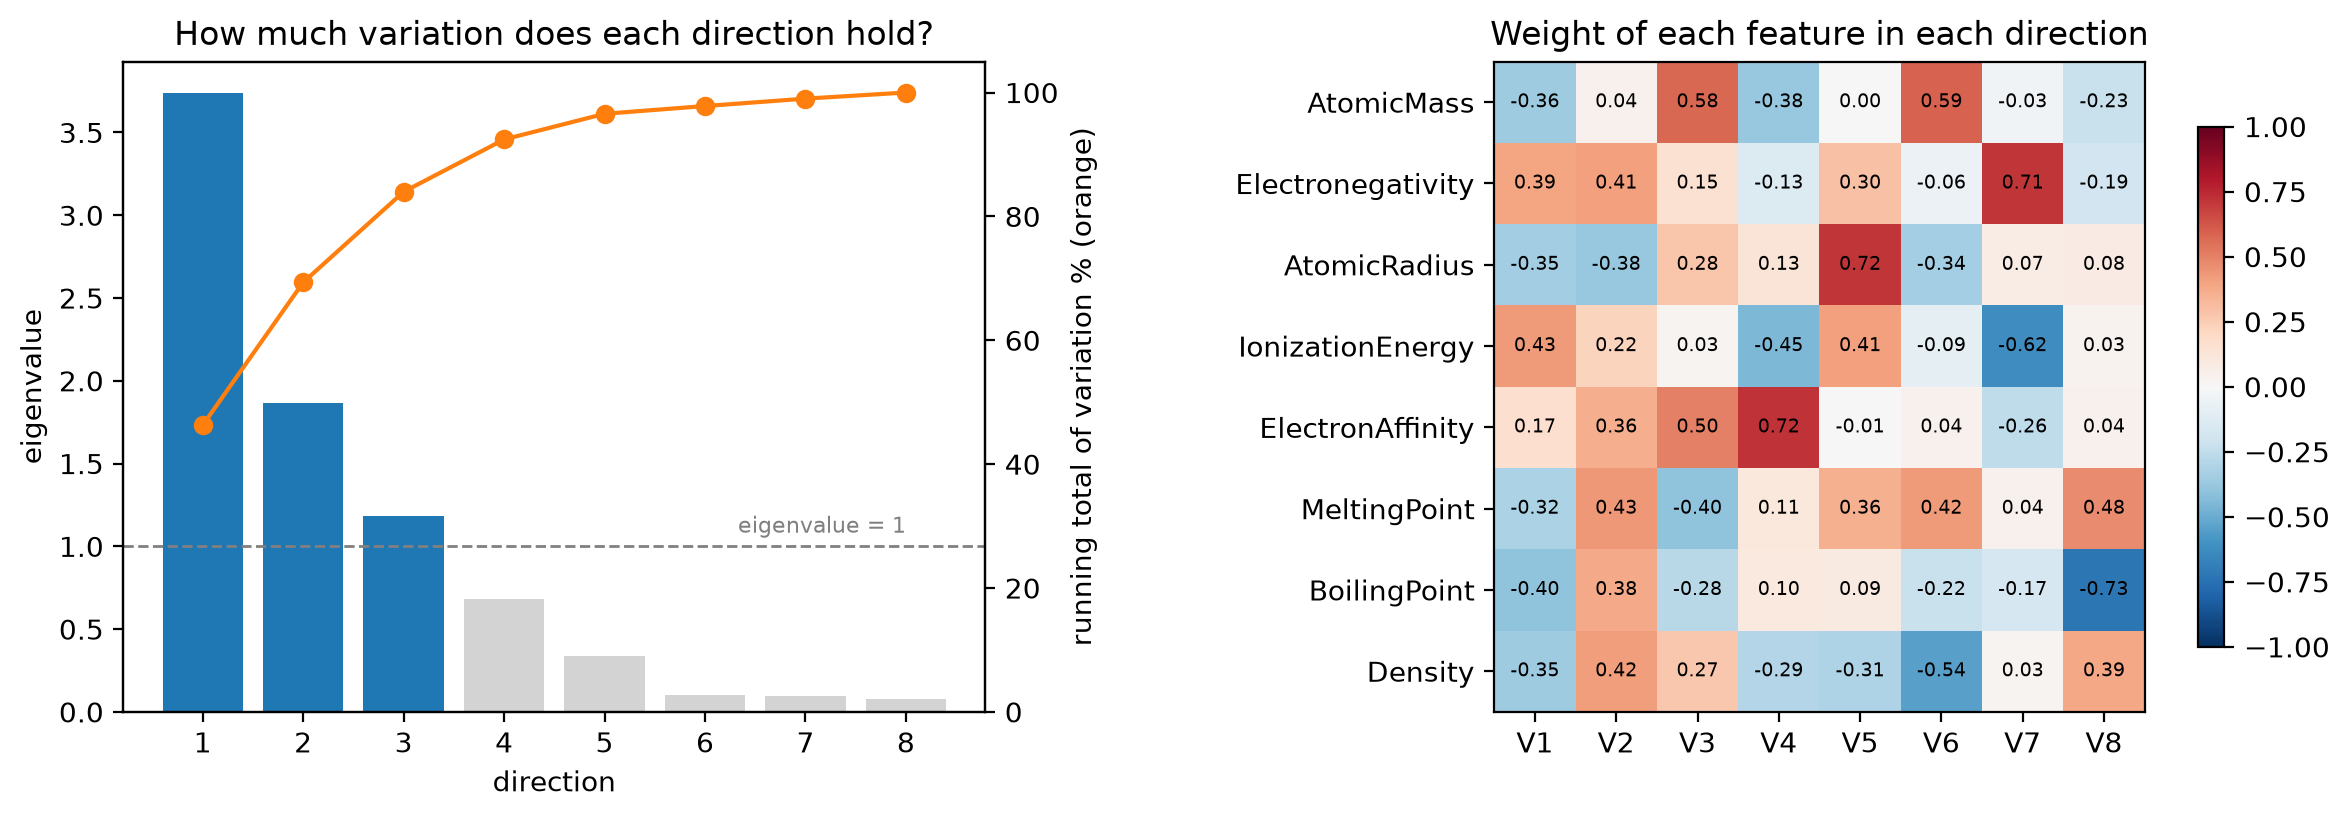

In [ ]:
_fig, (_ax1, _ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
_pcs = np.arange(1, len(eigenvalues) + 1)
_ax1.bar(_pcs, eigenvalues, color=["tab:blue" if _v > 1 else "lightgrey" for _v in eigenvalues])
_ax1.axhline(1, color="grey", ls="--", lw=1)
_ax1.text(len(_pcs), 1.05, "eigenvalue = 1", ha="right", va="bottom", color="grey", fontsize=8)
_ax1.set_xlabel("direction")
_ax1.set_ylabel("eigenvalue")
_ax1.set_title("How much variation does each direction hold?")
_ax1b = _ax1.twinx()
_ax1b.plot(_pcs, 100 * np.cumsum(explained), "o-", color="tab:orange")
_ax1b.set_ylim(0, 105)
_ax1b.set_ylabel("running total of variation % (orange)")

_im = _ax2.imshow(eigenvectors, cmap="RdBu_r", vmin=-1, vmax=1)
_ax2.set_xticks(range(len(_pcs)), [f"V{p}" for p in _pcs])
_ax2.set_yticks(range(len(FEATURES)), FEATURES)
for (_i, _j), _v in np.ndenumerate(eigenvectors):
    _ax2.text(_j, _i, f"{_v:.2f}", ha="center", va="center", fontsize=7)
_ax2.set_title("Weight of each feature in each direction")
_fig.colorbar(_im, ax=_ax2, shrink=0.8)
_fig.tight_layout()

mo.vstack(
    [
        mo.md(
            f"The first **{m_kaiser}** directions have an eigenvalue above 1 (blue bars). "
            f"Together they hold **{100 * explained[:m_kaiser].sum():.0f}%** of the variation. "
            f"So our default is **m = {m_kaiser}**. "
            "In the right chart, dark red or dark blue means a big weight. The sign does not matter, only the size."
        ),
        _fig,
    ]
)

In [ ]:
def pca_feature_scores(V, m, eigvals=None):
    """Song et al. (2010): c_j = sum_{p<=m} |V_pj|. With eigvals, weight |V_pj| by lambda_p."""
    weights = np.ones(m) if eigvals is None else eigvals[:m]
    return np.abs(V[:, :m]) @ weights


def rank_features(scores):
    """Rank 1 = largest score = most important feature."""
    return pd.Series(scores, index=FEATURES).rank(ascending=False, method="first").astype(int)


m_tangle = mo.ui.anywidget(
    TangleSlider(amount=m_kaiser, min_value=1, max_value=len(FEATURES), step=1, digits=0)
)
mo.vstack(
    [
        mo.md("### Score the features"),
        mo.md(f"Use the top {m_tangle} PCA directions to score the features."),
        mo.md(f"<small>Drag the blue number left or right to change m (1 to {len(FEATURES)}). All charts below update.</small>"),
    ]
)

Score the features Use the top PCA directions to score the features. Drag the blue number left or right to change m (1 to 8). All charts below update.

In [ ]:
n_directions = int(m_tangle.value["amount"])
_c = pca_feature_scores(eigenvectors, n_directions)
_cw = pca_feature_scores(eigenvectors, n_directions, eigenvalues)
ranking = pd.DataFrame(
    {
        "score c_j": _c,
        "rank": rank_features(_c),
        "λ-weighted score": _cw,
        "λ-weighted rank": rank_features(_cw),
    },
    index=FEATURES,
).sort_values("rank")

_parts = (
    pd.DataFrame(
        np.abs(eigenvectors[:, :n_directions]),
        index=FEATURES,
        columns=[f"V{p}" for p in range(1, n_directions + 1)],
    )
    .reset_index(names="feature")
    .melt(id_vars="feature", var_name="direction", value_name="abs_weight")
)
score_chart = (
    alt.Chart(_parts)
    .mark_bar()
    .encode(
        x=alt.X("sum(abs_weight):Q", title="score c_j = sum of |weights|"),
        y=alt.Y("feature:N", sort=list(ranking.index), title=None),
        color=alt.Color("direction:N", title="direction", scale=alt.Scale(scheme="tableau10")),
        order=alt.Order("direction:N"),
        tooltip=["feature:N", "direction:N", alt.Tooltip("abs_weight:Q", title="|weight|", format=".2f")],
    )
    .properties(
        width=560,
        height=260,
        title=f"Feature scores with the top {n_directions} directions ({100 * explained[:n_directions].sum():.0f}% of the variation)",
    )
)

mo.vstack(
    [
        mo.md(
            "Each bar is the score of one feature. The coloured pieces show how much each direction adds. "
            "**Hover** over a piece to see the number. Longest bar = most important feature."
        ),
        score_chart,
        deeper({"Show the scores as a table": ranking.round(3)}),
    ]
)

,score c_j,rank,λ-weighted score,λ-weighted rank
MeltingPoint,1.156,1,2.478,2
BoilingPoint,1.054,2,2.524,1
Density,1.039,3,2.417,3
ElectronAffinity,1.034,4,1.901,8
AtomicRadius,1.006,5,2.340,5
AtomicMass,0.975,6,2.096,6
Electronegativity,0.954,7,2.410,4
IonizationEnergy,0.681,8,2.051,7


In [ ]:
_your_order = list(guess.value["value"])
_compare = pd.DataFrame(
    {"your rank": pd.Series(range(1, len(FEATURES) + 1), index=_your_order), "PCA rank": ranking["rank"]}
).sort_values("PCA rank")
_rho = _compare.corr(method="spearman").iloc[0, 1]

if _your_order == sorted(FEATURES):
    _out = mo.callout(mo.md("Drag the list in **“Make a guess”** above to compare your guess with PCA."), kind="info")
else:
    _out = mo.vstack(
        [
            mo.md("### Your guess vs PCA"),
            mo.hstack(
                [
                    mo.stat(
                        f"{_rho:+.2f}",
                        label="Agreement (Spearman ρ)",
                        caption="+1 = same order, 0 = unrelated, −1 = reversed",
                        bordered=True,
                    ),
                    _compare,
                ],
                widths=[1, 2],
            ),
        ]
    )
_out

Go deeper · Does the ranking change with m? Yes, a lot. With only 8 features, each extra direction adds its own features with full weight. With m = 1 the score is just the first direction, which favours ionization energy, boiling point and electronegativity. With m = 8 the score uses all directions and says little.
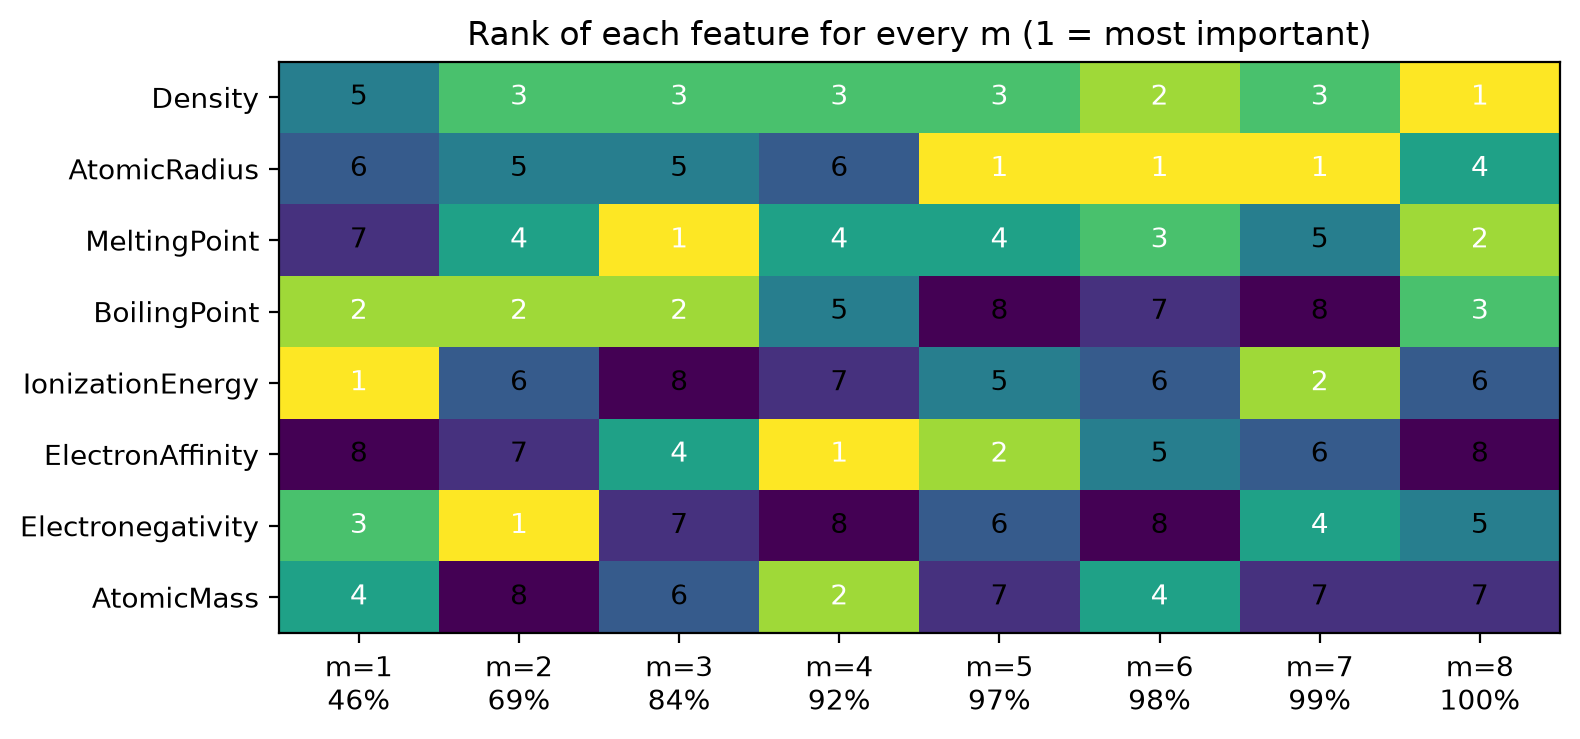

In [ ]:
rank_by_m = pd.DataFrame(
    {f"m={m}": rank_features(pca_feature_scores(eigenvectors, m)) for m in range(1, len(FEATURES) + 1)}
)
rank_by_m = rank_by_m.loc[rank_by_m.mean(axis=1).sort_values().index]

_fig, _ax = plt.subplots(figsize=(8, 3.8))
_ax.imshow(rank_by_m, cmap="viridis_r", aspect="auto")
for (_i, _j), _v in np.ndenumerate(rank_by_m.to_numpy()):
    _ax.text(_j, _i, _v, ha="center", va="center", color="w" if _v <= 4 else "k")
_ax.set_xticks(
    range(len(FEATURES)),
    [f"m={m}\n{100 * np.cumsum(explained)[m - 1]:.0f}%" for m in range(1, len(FEATURES) + 1)],
)
_ax.set_yticks(range(len(FEATURES)), rank_by_m.index)
_ax.set_title("Rank of each feature for every m (1 = most important)")
_fig.tight_layout()

deeper(
    {
        "Go deeper · Does the ranking change with m?": mo.vstack(
            [
                _fig,
                mo.md(
                    "Yes, a lot. With only 8 features, each extra direction adds its own features with full weight. "
                    "With m = 1 the score is just the first direction, which favours ionization energy, boiling point and electronegativity. "
                    "With m = 8 the score uses all directions and says little."
                ),
            ]
        )
    }
)

,rank (full data),bootstrap mean rank,bootstrap rank sd,P(top 3),P(bottom 3)
MeltingPoint,1,1.34,0.70,0.98,0.00
BoilingPoint,2,3.43,1.14,0.56,0.04
Density,3,3.91,1.72,0.43,0.23
AtomicMass,6,4.28,1.80,0.35,0.29
ElectronAffinity,4,4.35,2.13,0.39,0.36
AtomicRadius,5,4.87,1.59,0.25,0.41
Electronegativity,7,5.90,1.19,0.04,0.68
IonizationEnergy,8,7.92,0.38,0.00,1.00

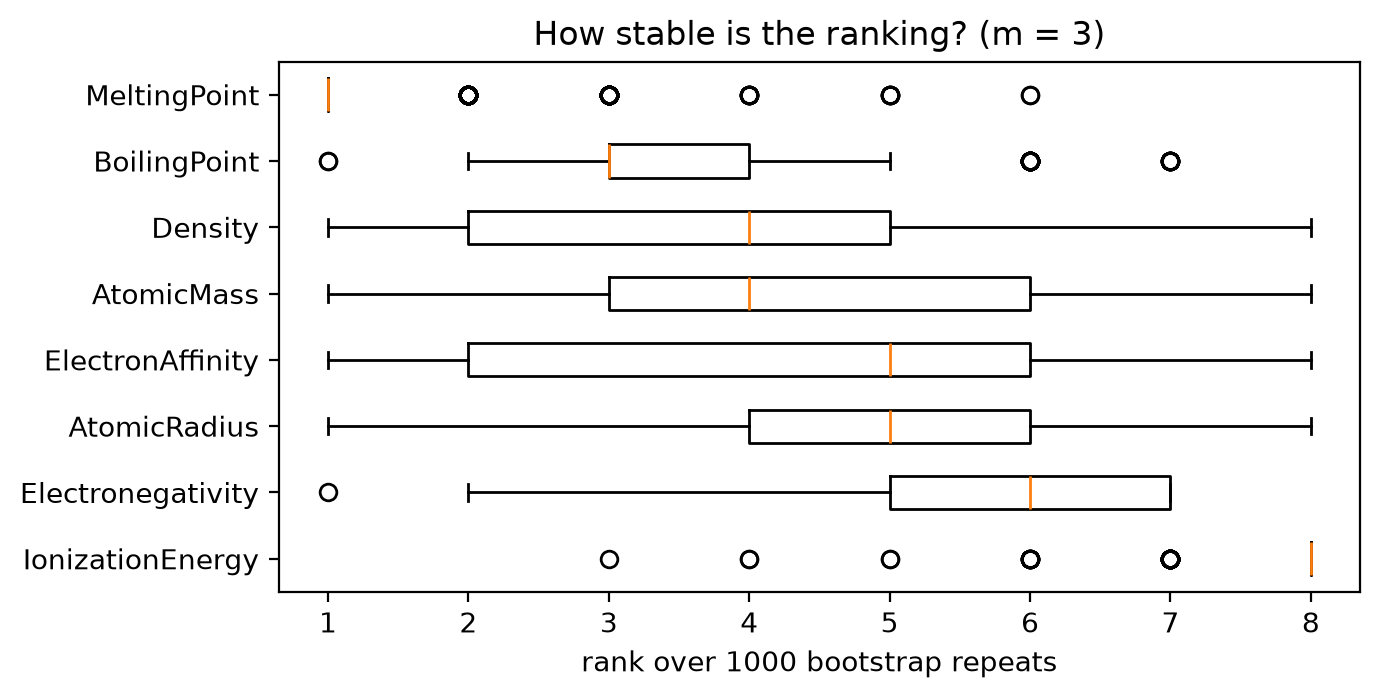

In [ ]:
def bootstrap_ranks(data, m, n_boot=1000, seed=0):
    """Re-run the Song et al. ranking on bootstrap resamples of the elements."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        sample = data[rng.integers(0, len(data), len(data))]
        sample = (sample - sample.mean(axis=0)) / sample.std(axis=0, ddof=1)
        vals, vecs = np.linalg.eigh(np.cov(sample, rowvar=False))
        out.append(rank_features(pca_feature_scores(vecs[:, np.argsort(vals)[::-1]], m)))
    return pd.DataFrame(out)


boot_ranks = bootstrap_ranks(X.to_numpy(), n_directions)
bootstrap_summary = pd.DataFrame(
    {
        "rank (full data)": ranking["rank"],
        "bootstrap mean rank": boot_ranks.mean(),
        "bootstrap rank sd": boot_ranks.std(),
        "P(top 3)": (boot_ranks <= 3).mean(),
        "P(bottom 3)": (boot_ranks >= len(FEATURES) - 2).mean(),
    }
).sort_values("bootstrap mean rank")

_fig, _ax = plt.subplots(figsize=(7, 3.6))
_ax.boxplot(
    [boot_ranks[f] for f in bootstrap_summary.index],
    tick_labels=bootstrap_summary.index,
    orientation="horizontal",
)
_ax.invert_yaxis()
_ax.set_xlabel("rank over 1000 bootstrap repeats")
_ax.set_title(f"How stable is the ranking? (m = {n_directions})")
_fig.tight_layout()

deeper(
    {
        "Go deeper · Is the ranking stable? (bootstrap)": mo.vstack(
            [
                mo.md(
                    "We draw 1000 new data sets by picking elements at random with replacement, "
                    "and rank the features again each time. A narrow box means a stable rank."
                ),
                _fig,
                bootstrap_summary.round(2),
            ]
        )
    }
)

In [ ]:
# The same method on the raw (not rescaled) covariance matrix, as the paper literally states.
_vals, _vecs = np.linalg.eigh(np.cov(X.to_numpy(), rowvar=False))
_order = np.argsort(_vals)[::-1]
raw_eigenvectors = _vecs[:, _order]
raw_explained = _vals[_order] / _vals.sum()
_c_raw = pca_feature_scores(raw_eigenvectors, n_directions)

raw_ranking = pd.DataFrame(
    {
        "variance (raw units)": X.var(),
        "|V1| raw": pd.Series(np.abs(raw_eigenvectors[:, 0]), index=FEATURES),
        "c_j raw covariance": pd.Series(_c_raw, index=FEATURES),
        "rank raw": rank_features(_c_raw),
        "rank rescaled": ranking["rank"],
    },
    index=FEATURES,
).sort_values("rank raw")

_top_pc1 = raw_ranking["|V1| raw"].nlargest(2)
deeper(
    {
        "Go deeper · Why we rescale the data first": mo.vstack(
            [
                mo.md(
                    f"Without rescaling, the first direction alone holds {100 * raw_explained[0]:.1f}% of the variation. "
                    f"It is almost only {_top_pc1.index[0]} ({_top_pc1.iloc[0]:.2f}) and {_top_pc1.index[1]} ({_top_pc1.iloc[1]:.2f}). "
                    "These are in kelvin, so their numbers are huge (variance near 10⁶). "
                    "The ranking then shows which feature has the biggest unit, not which feature carries information."
                ),
                raw_ranking.round(3),
            ]
        )
    }
)

,variance (raw units),|V1| raw,c_j raw covariance,rank raw,rank rescaled
MeltingPoint,814797.683,0.477,1.411,1,1
BoilingPoint,2429291.843,0.879,1.400,2,2
AtomicMass,5663.625,0.013,1.022,3,6
AtomicRadius,1487.578,0.004,0.356,4,5
Density,35.052,0.002,0.044,5,3
IonizationEnergy,11.427,0.001,0.016,6,8
Electronegativity,0.438,0.000,0.003,7,7
ElectronAffinity,0.628,0.000,0.000,8,4


,Song et al. top-n,λ-weighted top-n,random subset (mean),best subset,worst subset
n features kept,,,,,
1,0.285,0.348,0.298,0.349,0.178
2,0.408,0.408,0.512,0.618,0.408
3,0.531,0.531,0.671,0.781,0.531
4,0.688,0.778,0.786,0.875,0.620
5,0.876,0.859,0.868,0.936,0.773
6,0.903,0.886,0.927,0.963,0.859
7,0.975,0.930,0.969,0.984,0.930
8,1.000,1.000,1.000,1.000,1.000

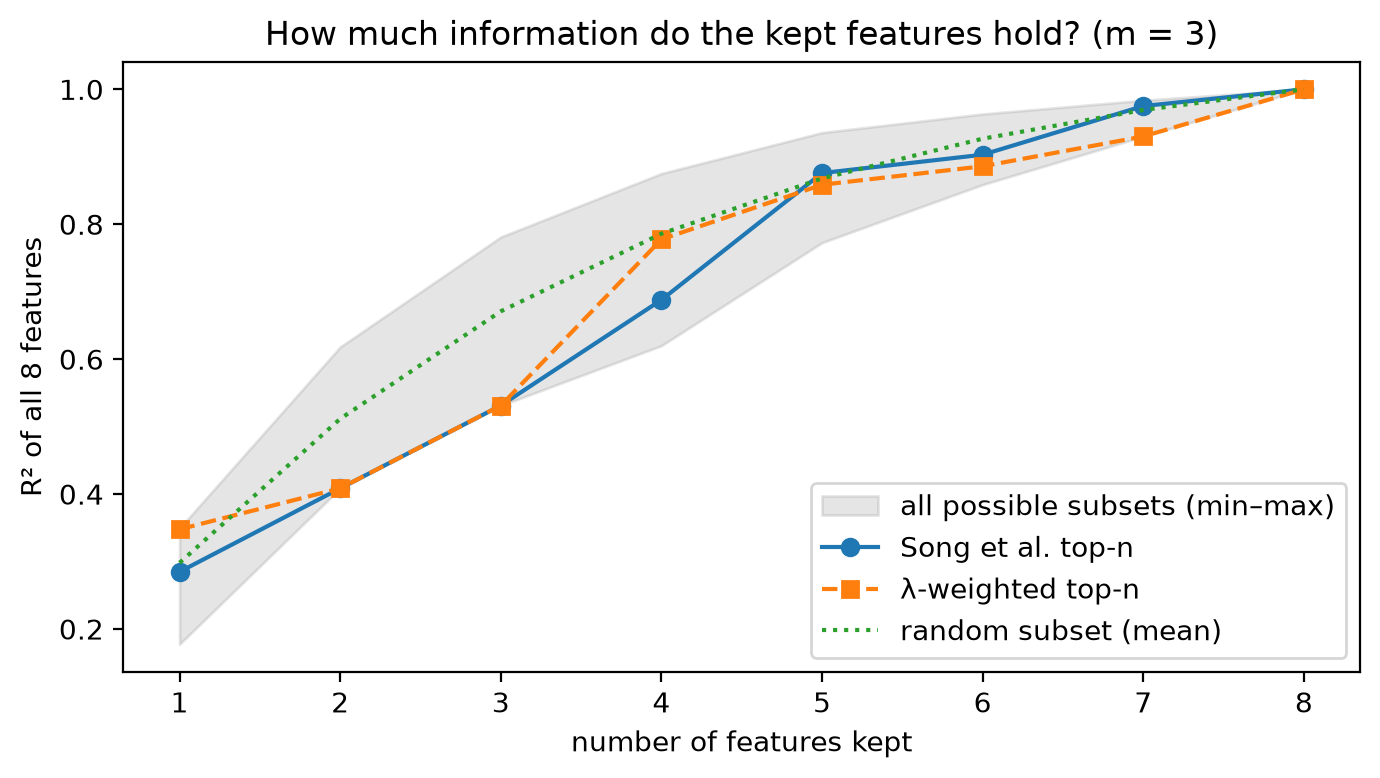

In [ ]:
def reconstruction_r2(cols):
    """Share of the variation of all 8 rescaled features that a linear model on `cols` explains."""
    idx = [FEATURES.index(c) for c in cols]
    pred = LinearRegression().fit(X_std[:, idx], X_std).predict(X_std[:, idx])
    return 1 - ((X_std - pred) ** 2).sum() / ((X_std - X_std.mean(axis=0)) ** 2).sum()


_rows = []
for _n in range(1, len(FEATURES) + 1):
    _all = [reconstruction_r2(_s) for _s in itertools.combinations(FEATURES, _n)]
    _rows.append(
        {
            "n features kept": _n,
            "Song et al. top-n": reconstruction_r2(list(ranking.index[:_n])),
            "λ-weighted top-n": reconstruction_r2(list(ranking.sort_values("λ-weighted rank").index[:_n])),
            "random subset (mean)": np.mean(_all),
            "best subset": np.max(_all),
            "worst subset": np.min(_all),
        }
    )
subset_r2 = pd.DataFrame(_rows).set_index("n features kept")

_fig, _ax = plt.subplots(figsize=(7, 4))
_ax.fill_between(subset_r2.index, subset_r2["worst subset"], subset_r2["best subset"], color="grey", alpha=0.2, label="all possible subsets (min–max)")
for _col, _style in [("Song et al. top-n", "o-"), ("λ-weighted top-n", "s--"), ("random subset (mean)", ":")]:
    _ax.plot(subset_r2.index, subset_r2[_col], _style, label=_col)
_ax.set_xlabel("number of features kept")
_ax.set_ylabel("R² of all 8 features")
_ax.set_title(f"How much information do the kept features hold? (m = {n_directions})")
_ax.legend()
_fig.tight_layout()

deeper(
    {
        "Go deeper · Do the top features keep the information?": mo.vstack(
            [
                mo.md(
                    "We keep the top $n$ features and try to predict all 8 features from them with a linear model. "
                    "$R^2$ = 1 means nothing is lost. The grey band shows the worst and the best of all possible sets of $n$ features."
                ),
                _fig,
                subset_r2.round(3),
            ]
        )
    }
)

In [ ]:
# The answer uses the default m (Kaiser rule), so it does not move with the slider.
_rank = rank_features(pca_feature_scores(eigenvectors, m_kaiser)).sort_values()
_order = list(_rank.index)
_boot = bootstrap_ranks(X.to_numpy(), m_kaiser)
_p_top = (_boot[_order[0]] <= 3).mean()
_p_last = (_boot[_order[-1]] >= len(FEATURES) - 2).mean()
_corr = pd.DataFrame(X_std, columns=FEATURES).corr()
_r2_top3 = reconstruction_r2(_order[:3])
_r2_rand3 = np.mean([reconstruction_r2(s) for s in itertools.combinations(FEATURES, 3)])

mo.callout(
    mo.md(
        f"""
### Answer to Q1

With the top **{m_kaiser}** directions ({100 * explained[:m_kaiser].sum():.0f}% of the variation), the PCA ranking is:

{chr(10).join(f"{i + 1}. **{f}**" if i < 3 else f"{i + 1}. {f}" for i, f in enumerate(_order))}

**What this means**

- **{_order[0]}** is the most important feature. It has a large weight in all {m_kaiser} top directions.
- **{_order[-1]}** is the least important. It has a large weight in the first direction only. The method adds all {m_kaiser} directions with the same weight, so this does not help it.
- The top and the bottom of the list are **stable**. In 1000 bootstrap repeats, {_order[0]} stays in the top 3 in {100 * _p_top:.0f}% of cases, and {_order[-1]} stays in the bottom 3 in {100 * _p_last:.0f}% of cases.
- The **middle** of the list is not stable. It changes with $m$ and with small changes in the data.

**Limit of the method**

The method does not see when two features carry the same information. Melting point and boiling point are strongly linked (r = {_corr.loc['MeltingPoint', 'BoilingPoint']:.2f}), so both get a high score.
As a result, the top 3 features keep only R² = {_r2_top3:.2f} of the information in all 8 features. Three random features keep {_r2_rand3:.2f} on average.
So the method is good to find the features that drive the main patterns. It is not good to find the smallest set of features without repeats.
"""
    ),
    kind="success",
)

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003ch3 id=\"answer-to-q1\"\u003eAnswer to Q1\u003c/h3\u003e\n\u003cspan class=\"paragraph\"\u003eWith the top \u003cstrong\u003e3\u003c/strong\u003e directions (84% of the variation), the PCA ranking is:\u003c/span\u003e\n\u003col\u003e\n\u003cli\u003e\u003cstrong\u003eMeltingPoint\u003c/strong\u003e\u003c/li\u003e\n\u003cli\u003e\u003cstrong\u003eBoilingPoint\u003c/strong\u003e\u003c/li\u003e\n\u003cli\u003e\u003cstrong\u003eDensity\u003c/strong\u003e\u003c/li\u003e\n\u003cli\u003eElectronAffinity\u003c/li\u003e\n\u003cli\u003eAtomicRadius\u003c/li\u003e\n\u003cli\u003eAtomicMass\u003c/li\u003e\n\u003cli\u003eElectronegativity\u003c/li\u003e\n\u003cli\u003eIonizationEnergy\u003c/li\u003e\n\u003c/ol\u003e\n\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eWhat this means\u003c/strong\u003e\u003c/span\u003e\n\u003cul\u003e\n\u003cli\u003e\u003cstrong\u003eMeltingPoint\u003c/strong\u003e is the most important feature. It has a large weight in all 3 top directions.\u003c/li\u003e\n\u003cli\u003e\u003cstrong\u003eIonizationEnergy\u003c/strong\u003e is the least important. It has a large weight in the first direction only. The method adds all 3 directions with the same weight, so this does not help it.\u003c/li\u003e\n\u003cli\u003eThe top and the bottom of the list are \u003cstrong\u003estable\u003c/strong\u003e. In 1000 bootstrap repeats, MeltingPoint stays in the top 3 in 98% of cases, and IonizationEnergy stays in the bottom 3 in 100% of cases.\u003c/li\u003e\n\u003cli\u003eThe \u003cstrong\u003emiddle\u003c/strong\u003e of the list is not stable. It changes with \u003cmarimo-tex class=\"arithmatex\"\u003e||(m||)\u003c/marimo-tex\u003e and with small changes in the data.\u003c/li\u003e\n\u003c/ul\u003e\n\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eLimit of the method\u003c/strong\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eThe method does not see when two features carry the same information. Melting point and boiling point are strongly linked (r = 0.88), so both get a high score.\nAs a result, the top 3 features keep only R² = 0.53 of the information in all 8 features. Three random features keep 0.67 on average.\nSo the method is good to find the features that drive the main patterns. It is not good to find the smallest set of features without repeats.\u003c/span\u003e\u003c/span\u003e"' data-kind='"success"'>

In [ ]:
mo.vstack(
    [
        mo.md(
            r"""
## Q2 · Do the clusters match the periodic table?

### Plan in plain words

1. **k-means** puts the 99 elements into $k$ groups (clusters), using only the 8 rescaled features. Elements in one cluster have similar features. k-means does **not** know where an element sits in the table.
2. We **colour the periodic table** by cluster and look.
3. We **test** it: are neighbours in the table in the same cluster more often than by chance?
"""
        ),
        mo.mermaid(
            """
graph LR
  A["8 features"] --> B["k-means"] --> C["cluster of<br/>each element"]
  D["position in the table<br/>(NOT given to k-means)"] --> E{"Do neighbours<br/>share a cluster?"}
  C --> E
"""
        ),
    ]
)

Q2 · Do the clusters match the periodic table? 
 Plan in plain words 
 
 k-means puts the 99 elements into ||(k||) groups (clusters), using only the 8 rescaled features. Elements in one cluster have similar features. k-means does not know where an element sits in the table. 
 We colour the periodic table by cluster and look. 
 We test it: are neighbours in the table in the same cluster more often than by chance?

,inertia,silhouette,ARI vs GroupBlock,NMI vs GroupBlock
k,,,,
2,546.667,0.367,0.129,0.321
3,436.535,0.242,0.146,0.431
4,360.183,0.241,0.247,0.466
5,306.252,0.270,0.279,0.517
6,260.319,0.299,0.389,0.635
7,230.453,0.288,0.420,0.663
8,208.257,0.273,0.484,0.695
9,185.584,0.297,0.463,0.654
10,171.744,0.291,0.477,0.660

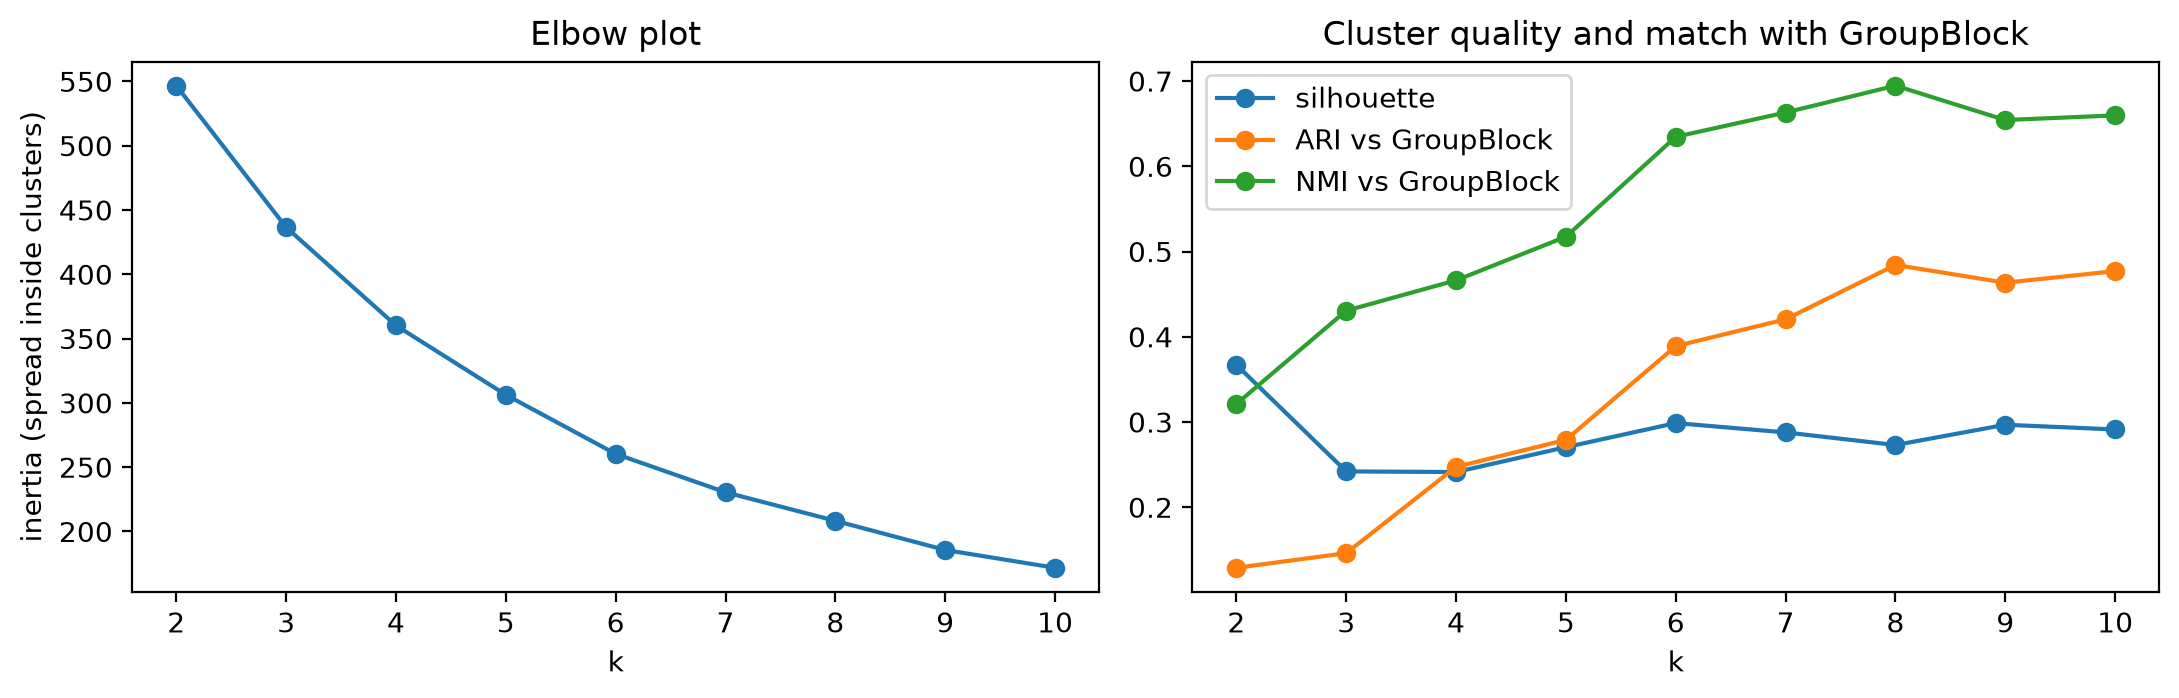

In [ ]:
_rows = []
for _k in range(2, 11):
    _km = KMeans(n_clusters=_k, n_init=50, random_state=0).fit(X_std)
    _rows.append(
        {
            "k": _k,
            "inertia": _km.inertia_,
            "silhouette": silhouette_score(X_std, _km.labels_),
            "ARI vs GroupBlock": adjusted_rand_score(elements["GroupBlock"], _km.labels_),
            "NMI vs GroupBlock": normalized_mutual_info_score(elements["GroupBlock"], _km.labels_),
        }
    )
k_sweep = pd.DataFrame(_rows).set_index("k")

_fig, (_ax1, _ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
_ax1.plot(k_sweep.index, k_sweep["inertia"], "o-")
_ax1.set_xlabel("k")
_ax1.set_ylabel("inertia (spread inside clusters)")
_ax1.set_title("Elbow plot")
for _col in ["silhouette", "ARI vs GroupBlock", "NMI vs GroupBlock"]:
    _ax2.plot(k_sweep.index, k_sweep[_col], "o-", label=_col)
_ax2.set_xlabel("k")
_ax2.set_title("Cluster quality and match with GroupBlock")
_ax2.legend()
_fig.tight_layout()

deeper(
    {
        "How we picked k": mo.vstack(
            [
                mo.md(
                    "- **Inertia** is the spread inside the clusters. It always falls as $k$ grows; we look for a bend (elbow).\n"
                    "- **Silhouette** (−1 to 1) is high when clusters are tight and far apart.\n"
                    "- **ARI / NMI** show the match with the chemical families in `GroupBlock` (0 = chance, 1 = perfect)."
                ),
                _fig,
                k_sweep.round(3),
            ]
        )
    }
)

In [ ]:
K_DEFAULT = 6
k_tangle = mo.ui.anywidget(TangleSlider(amount=K_DEFAULT, min_value=2, max_value=10, step=1, digits=0))

_s = k_sweep["silhouette"]
mo.vstack(
    [
        mo.md("### Make the clusters"),
        mo.md(f"Split the elements into {k_tangle} clusters."),
        mo.md("<small>Drag the blue number (2 to 10). Everything below updates.</small>"),
        mo.md(
            f"**Why {K_DEFAULT}?** k = 2 has the best silhouette ({_s[2]:.2f}), but it only cuts the elements into two big halves. That is too rough to compare with the table. "
            f"For k ≥ 3, the silhouette is highest at k = {K_DEFAULT} ({_s[K_DEFAULT]:.2f}), and the elbow plot bends there. "
            f"The match with the chemical families also grows from ARI {k_sweep.loc[2, 'ARI vs GroupBlock']:.2f} (k = 2) to {k_sweep.loc[K_DEFAULT, 'ARI vs GroupBlock']:.2f} (k = {K_DEFAULT})."
        ),
    ]
)

Make the clusters Split the elements into clusters. Drag the blue number (2 to 10). Everything below updates. Why 6? k = 2 has the best silhouette (0.37), but it only cuts the elements into two big halves. That is too rough to compare with the table. For k ≥ 3, the silhouette is highest at k = 6 (0.30), and the elbow plot bends there. The match with the chemical families also grows from ARI 0.13 (k = 2) to 0.39 (k = 6).

In [ ]:
n_clusters = int(k_tangle.value["amount"])
_raw_labels = KMeans(n_clusters=n_clusters, n_init=50, random_state=0).fit_predict(X_std)

# Number the clusters 1..k in order of their lightest element, so the names stay stable.
_first_seen = pd.Series(_raw_labels).drop_duplicates().tolist()
labels = np.array([_first_seen.index(_l) + 1 for _l in _raw_labels])
clustered = elements.assign(Cluster=labels)

# Name each cluster after its most common chemical family.
_main = clustered.groupby("Cluster")["GroupBlock"].agg(
    lambda s: f"{s.value_counts().index[0]} ({s.value_counts().iloc[0]}/{len(s)})"
)
cluster_names = {k: f"C{k} · mostly {_main[k]}" for k in _main.index}
clustered["ClusterName"] = clustered["Cluster"].map(cluster_names)
CLUSTER_COLORS = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2", "#59a14f", "#edc948", "#b07aa1", "#ff9da7", "#9c755f", "#bab0ac"]

cluster_profile = (
    clustered.groupby("Cluster")
    .agg(name=("ClusterName", "first"), size=("Symbol", "size"), members=("Symbol", " ".join))
    .join(X.assign(Cluster=labels).groupby("Cluster").mean().round(2))
)
mo.vstack(
    [
        cluster_profile[["name", "size", "members"]],
        deeper({"Show the average features of each cluster": cluster_profile.drop(columns=["name", "members"]).T.rename(columns=lambda k: f"C{k}")}),
    ]
)

name size members Cluster 1 C1 · mostly Noble gas (6/10) 10 H He N O Ne P Ar Kr Xe Rn 2 C2 · mostly Transition metal (15/27) 27 Li Be B Mg Al Si Sc Ti V Cr Mn Fe Co Ni Cu Zn Ga Ge As Y Zr Pd Ag Cd In Sn Sb 3 C3 · mostly Transition metal (13/14) 14 C Nb Mo Tc Ru Rh Hf Ta W Re Os Ir Pt Au 4 C4 · mostly Halogen (5/9) 9 F S Cl Se Br Te I Po At 5 C5 · mostly Alkali metal (5/9) 9 Na K Ca Rb Sr Cs Ba Fr Ra 6 C6 · mostly Lanthanide (15/30) 30 La Ce Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm Yb Lu Hg Tl Pb Bi Ac Th Pa U Np Pu Am Cm Bk Cf Es Show the average features of each cluster Cluster C1 C2 C3 C4 C5 C6 size 10.00 27.00 14.00 9.00 9.00 30.00 AtomicMass 56.32 64.40 143.27 102.10 110.50 193.66 Electronegativity 2.74 1.72 2.07 2.69 0.87 1.34 AtomicRadius 172.70 185.96 203.29 185.11 280.78 231.67 IonizationEnergy 15.10 7.52 8.13 11.08 4.86 6.16 ElectronAffinity 0.30 0.56 1.05 2.68 0.27 0.48 MeltingPoint 103.71 1367.51 2792.63 398.29 639.95 1296.48 BoilingPoint 135.65 2742.52 4748.07 720.39 1406.94 3042.65 Density 0.18 5.99 15.15 4.16 2.44 11.04

In [ ]:
_cells = (
    clean[["Symbol", "Name", "AtomicNumber", "Row", "Column", "GroupBlock"]]
    .merge(clustered[["Symbol", "ClusterName"]], on="Symbol", how="left")
    .merge(X.round(2).reset_index(), on="Symbol", how="left")
)
_cells["ClusterName"] = _cells["ClusterName"].fillna("not clustered (Z ≥ 100)")
_domain = list(cluster_names.values()) + ["not clustered (Z ≥ 100)"]
_colors = CLUSTER_COLORS[: len(cluster_names)] + ["#e8e8e8"]

_pick = alt.selection_point(fields=["ClusterName"], name="pick")
_base = alt.Chart(_cells).encode(
    x=alt.X("Column:O", scale=alt.Scale(domain=list(range(1, 19))), axis=None),
    y=alt.Y("Row:O", scale=alt.Scale(domain=list(range(1, 11))), axis=None),
    tooltip=["Name:N", "Symbol:N", "AtomicNumber:Q", "GroupBlock:N", "ClusterName:N", *[f"{f}:Q" for f in FEATURES]],
)
_tiles = (
    _base.mark_rect(stroke="white", strokeWidth=2, cornerRadius=4)
    .encode(
        color=alt.Color(
            "ClusterName:N",
            title="Cluster",
            scale=alt.Scale(domain=_domain, range=_colors),
            legend=alt.Legend(orient="bottom", columns=2, labelLimit=320),
        ),
        opacity=alt.condition(_pick, alt.value(1.0), alt.value(0.2)),
    )
    .add_params(_pick)
)
_symbols = _base.mark_text(fontSize=12, fontWeight="bold").encode(text="Symbol:N")
table_chart = (_tiles + _symbols).properties(
    width=760,
    height=430,
    title=f"k-means clusters (k = {n_clusters}) on the periodic table. k-means never saw the positions.",
)
periodic_chart = mo.ui.altair_chart(table_chart)
mo.vstack(
    [
        mo.md("**Click** an element to light up its cluster (click empty space to reset). **Hover** to see its data. Rows 9–10 are the lanthanides and actinides."),
        periodic_chart,
    ]
)

Click an element to light up its cluster (click empty space to reset). Hover to see its data. Rows 9–10 are the lanthanides and actinides. <marimo-vega data-initial-value='{}' data-label='null' data-spec='{"config":{"view":{"continuousWidth":300,"continuousHeight":300}},"layer":[{"mark":{"type":"rect","cornerRadius":4,"stroke":"white","strokeWidth":2},"encoding":{"color":{"field":"ClusterName","legend":{"columns":2,"labelLimit":320,"orient":"bottom"},"scale":{"domain":["C1 · mostly Noble gas (6/10)","C2 · mostly Transition metal (15/27)","C3 · mostly Transition metal (13/14)","C4 · mostly Halogen (5/9)","C5 · mostly Alkali metal (5/9)","C6 · mostly Lanthanide (15/30)","not clustered (Z ≥ 100)"],"range":["#4e79a7","#f28e2b","#e15759","#76b7b2","#59a14f","#edc948","#e8e8e8"]},"title":"Cluster","type":"nominal"},"opacity":{"condition":{"param":"pick","value":1.0},"value":0.2},"tooltip":[{"field":"Name","type":"nominal"},{"field":"Symbol","type":"nominal"},{"field":"AtomicNumber","type":"quantitative"},{"field":"GroupBlock","type":"nominal"},{"field":"ClusterName","type":"nominal"},{"field":"AtomicMass","type":"quantitative"},{"field":"Electronegativity","type":"quantitative"},{"field":"AtomicRadius","type":"quantitative"},{"field":"IonizationEnergy","type":"quantitative"},{"field":"ElectronAffinity","type":"quantitative"},{"field":"MeltingPoint","type":"quantitative"},{"field":"BoilingPoint","type":"quantitative"},{"field":"Density","type":"quantitative"}],"x":{"axis":null,"field":"Column","scale":{"domain":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18]},"type":"ordinal"},"y":{"axis":null,"field":"Row","scale":{"domain":[1,2,3,4,5,6,7,8,9,10]},"type":"ordinal"}},"name":"view_5cea4b1d5b7e82ee_0"},{"mark":{"type":"text","fontSize":12,"fontWeight":"bold"},"encoding":{"text":{"field":"Symbol","type":"nominal"},"tooltip":[{"field":"Name","type":"nominal"},{"field":"Symbol","type":"nominal"},{"field":"AtomicNumber","type":"quantitative"},{"field":"GroupBlock","type":"nominal"},{"field":"ClusterName","type":"nominal"},{"field":"AtomicMass","type":"quantitative"},{"field":"Electronegativity","type":"quantitative"},{"field":"AtomicRadius","type":"quantitative"},{"field":"IonizationEnergy","type":"quantitative"},{"field":"ElectronAffinity","type":"quantitative"},{"field":"MeltingPoint","type":"quantitative"},{"field":"BoilingPoint","type":"quantitative"},{"field":"Density","type":"quantitative"}],"x":{"axis":null,"field":"Column","scale":{"domain":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18]},"type":"ordinal"},"y":{"axis":null,"field":"Row","scale":{"domain":[1,2,3,4,5,6,7,8,9,10]},"type":"ordinal"}}}],"data":{"url":"...","format":{"type":"arrow"}},"height":430,"params":[{"name":"pick","select":{"type":"point","fields":["ClusterName"]},"views":["view_5cea4b1d5b7e82ee_0"]}],"title":"k-means clusters (k = 6) on the periodic table. k-means never saw the positions.","width":760,"$schema":"https://vega.github.io/schema/vega-lite/v6.4.1.json"}' data-chart-selection='false' data-field-selection='true' data-embed-options='{}'>

In [ ]:
_sel = periodic_chart.value
_names = set() if _sel is None or len(_sel) == 0 else set(_sel["ClusterName"])
_name = next(iter(_names)) if len(_names) == 1 else None

if _name is None or _name not in cluster_names.values():
    _out = mo.callout(mo.md("Click an element in the table above to see the fingerprint of its cluster here."), kind="info")
else:
    _k = next(k for k, v in cluster_names.items() if v == _name)
    _members = clustered.loc[clustered["Cluster"] == _k, "Symbol"]
    _profile = (
        pd.DataFrame(X_std, columns=FEATURES)[labels == _k]
        .mean()
        .rename("average (rescaled)")
        .reset_index(names="feature")
    )
    _bar = (
        alt.Chart(_profile)
        .mark_bar(color=CLUSTER_COLORS[_k - 1])
        .encode(
            x=alt.X("average (rescaled):Q", title="average of the cluster (0 = average of all elements)"),
            y=alt.Y("feature:N", sort=FEATURES, title=None),
            tooltip=["feature:N", alt.Tooltip("average (rescaled):Q", format=".2f")],
        )
        .properties(width=480, height=220, title=f"What makes {_name} special?")
    )
    _out = mo.vstack(
        [
            mo.md(f"**{_name}** has {len(_members)} elements: {', '.join(_members)}."),
            _bar,
            mo.md("<small>Bars to the right: higher than a typical element. Bars to the left: lower.</small>"),
        ]
    )
_out

In [ ]:
parallel = mo.ui.anywidget(
    ParallelCoordinates(
        X.round(2).reset_index().assign(Cluster=[f"C{k}" for k in labels]),
        color_by="Cluster",
        color_map={f"C{k}": CLUSTER_COLORS[k - 1] for k in cluster_names},
        height=460,
    )
)
mo.vstack(
    [
        mo.md(
            "### Cluster fingerprints\n"
            "Each line is one element. Each vertical axis is one feature (in its own units). "
            "Lines of one colour follow a similar path: the elements in a cluster have similar features. "
            "**Drag along an axis** to keep only the elements in that range. Cluster names (C1, C2, …) are the same as in the table above."
        ),
        parallel,
    ]
)

Cluster fingerprints 
 Each line is one element. Each vertical axis is one feature (in its own units). Lines of one colour follow a similar path: the elements in a cluster have similar features. Drag along an axis to keep only the elements in that range. Cluster names (C1, C2, …) are the same as in the table above.

In [ ]:
_refs = ["GroupBlock", "Block", "Group", "Period"]
cluster_agreement = pd.DataFrame(
    {
        "ARI": {c: adjusted_rand_score(clustered[c], labels) for c in _refs},
        "NMI": {c: normalized_mutual_info_score(clustered[c], labels) for c in _refs},
        "n categories": {c: clustered[c].nunique() for c in _refs},
    }
)

_group_order = [str(g) for g in range(1, 19)] + ["f-block"]
_cluster_name = clustered["ClusterName"].rename("Cluster")
mo.vstack(
    [
        mo.md(
            "### Do the clusters follow the chemical families?\n"
            "ARI = 0 means no better than chance, 1 means a perfect match. "
            "Each table counts how many elements of each family (rows) fall in each cluster (columns)."
        ),
        cluster_agreement.round(3),
        mo.ui.tabs(
            {
                "Family (GroupBlock)": pd.crosstab(clustered["GroupBlock"], _cluster_name),
                "Block (s/p/d/f)": pd.crosstab(clustered["Block"], _cluster_name),
                "Group": pd.crosstab(clustered["Group"], _cluster_name).reindex(_group_order, fill_value=0),
                "Period": pd.crosstab(clustered["Period"], _cluster_name),
            }
        ),
    ]
)

Do the clusters follow the chemical families? 
 ARI = 0 means no better than chance, 1 means a perfect match. Each table counts how many elements of each family (rows) fall in each cluster (columns). ARI NMI n categories GroupBlock 0.389 0.635 10 Block 0.397 0.539 4 Group 0.424 0.555 19 Period 0.255 0.370 7 <marimo-tabs data-initial-value='""' data-label='null' data-tabs='["\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eFamily (GroupBlock)\u003c/span\u003e\u003c/span\u003e","\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eBlock (s/p/d/f)\u003c/span\u003e\u003c/span\u003e","\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eGroup\u003c/span\u003e\u003c/span\u003e","\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003ePeriod\u003c/span\u003e\u003c/span\u003e"]' data-orientation='"horizontal"'> Cluster C1 · mostly Noble gas (6/10) C2 · mostly Transition metal (15/27) C3 · mostly Transition metal (13/14) C4 · mostly Halogen (5/9) C5 · mostly Alkali metal (5/9) C6 · mostly Lanthanide (15/30) GroupBlock Actinide 0 0 0 0 0 11 Alkali metal 0 1 0 0 5 0 Alkaline earth metal 0 2 0 0 4 0 Halogen 0 0 0 5 0 0 Lanthanide 0 0 0 0 0 15 Metalloid 0 5 0 2 0 0 Noble gas 6 0 0 0 0 0 Nonmetal 4 0 1 2 0 0 Post-transition metal 0 4 0 0 0 3 Transition metal 0 15 13 0 0 1 Cluster C1 · mostly Noble gas (6/10) C2 · mostly Transition metal (15/27) C3 · mostly Transition metal (13/14) C4 · mostly Halogen (5/9) C5 · mostly Alkali metal (5/9) C6 · mostly Lanthanide (15/30) Block d 0 15 13 0 0 3 f 0 0 0 0 0 24 p 8 9 1 9 0 3 s 2 3 0 0 9 0 Cluster C1 · mostly Noble gas (6/10) C2 · mostly Transition metal (15/27) C3 · mostly Transition metal (13/14) C4 · mostly Halogen (5/9) C5 · mostly Alkali metal (5/9) C6 · mostly Lanthanide (15/30) Group 1 1 1 0 0 5 0 2 0 2 0 0 4 0 3 0 2 0 0 0 2 4 0 2 1 0 0 0 5 0 1 2 0 0 0 ... ... ... ... ... ... ... 15 2 2 0 0 0 1 16 1 0 0 4 0 0 17 0 0 0 5 0 0 18 6 0 0 0 0 0 f-block 0 0 0 0 0 24 19 rows × 6 columns Cluster C1 · mostly Noble gas (6/10) C2 · mostly Transition metal (15/27) C3 · mostly Transition metal (13/14) C4 · mostly Halogen (5/9) C5 · mostly Alkali metal (5/9) C6 · mostly Lanthanide (15/30) Period 1 2 0 0 0 0 0 2 3 3 1 1 0 0 3 2 3 0 2 1 0 4 1 13 0 2 2 0 5 1 8 5 2 2 0 6 1 0 8 2 2 19 7 0 0 0 0 2 11

,n pairs,observed same-cluster share,null mean,null 99.9th pct,p-value (one-sided)
pairs,,,,,
all touching pairs,154,0.7338,0.2046,0.2987,0.0002
same group (up–down),67,0.7164,0.2044,0.3731,0.0002
same period (left–right),87,0.7471,0.2047,0.3333,0.0002

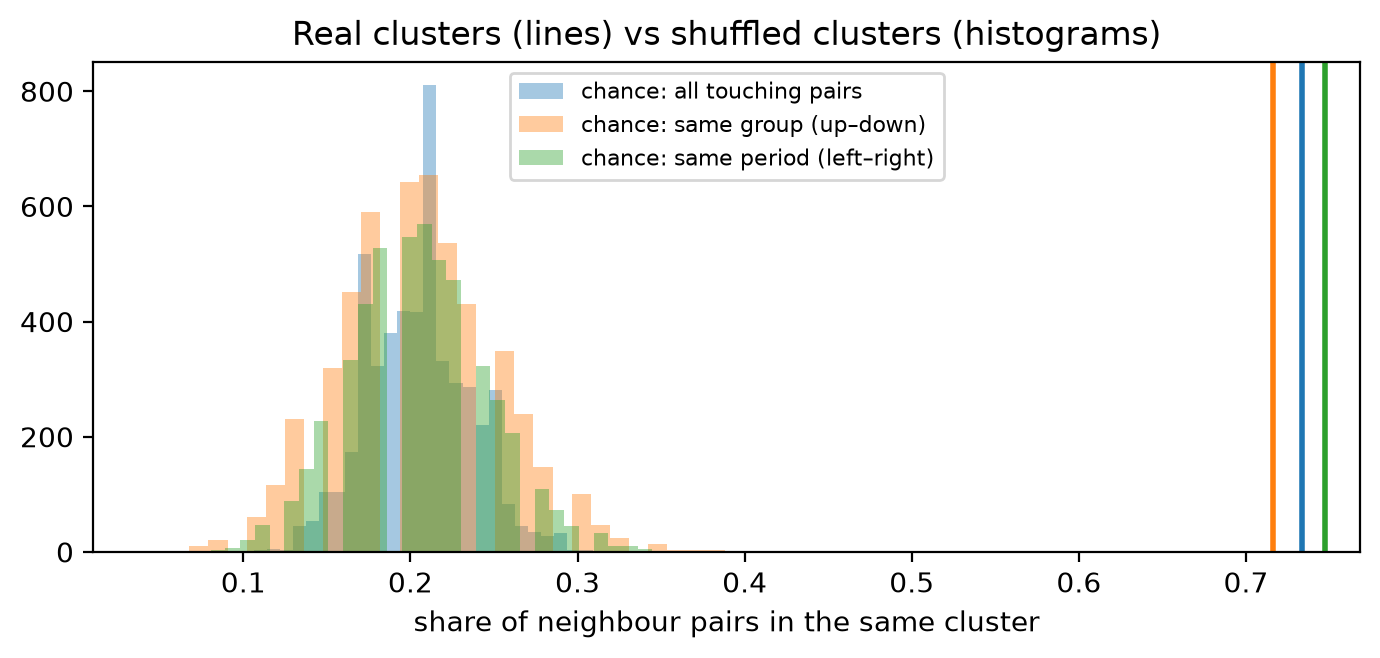

In [ ]:
def touching_pairs(table):
    """Pairs of rows of `table` whose elements touch in the printed periodic table (left-right or up-down)."""
    index_at = {(r, c): i for i, (r, c) in enumerate(zip(table["Row"], table["Column"]))}
    return pd.DataFrame(
        [
            (i, index_at[(r + dr, c + dc)], "same period (left–right)" if dr == 0 else "same group (up–down)")
            for (r, c), i in index_at.items()
            for dr, dc in [(0, 1), (1, 0)]
            if (r + dr, c + dc) in index_at
        ],
        columns=["a", "b", "direction"],
    )


def same_cluster_share(lab, pairs):
    return float(np.mean(lab[pairs["a"].to_numpy()] == lab[pairs["b"].to_numpy()]))


def proximity_test(lab, pairs, n_shuffles=5000, seed=0):
    """Observed same-cluster share of touching pairs vs shuffled labels (same cluster sizes)."""
    rng = np.random.default_rng(seed)
    null = np.array([same_cluster_share(rng.permutation(lab), pairs) for _ in range(n_shuffles)])
    observed = same_cluster_share(lab, pairs)
    return observed, null, (1 + (null >= observed).sum()) / (1 + n_shuffles)


neighbor_pairs = touching_pairs(clustered)
_rows, _nulls = [], {}
for _name, _pairs in [("all touching pairs", neighbor_pairs), *neighbor_pairs.groupby("direction")]:
    _obs, _nulls[_name], _p = proximity_test(labels, _pairs)
    _rows.append(
        {
            "pairs": _name,
            "n pairs": len(_pairs),
            "observed same-cluster share": _obs,
            "null mean": _nulls[_name].mean(),
            "null 99.9th pct": np.quantile(_nulls[_name], 0.999),
            "p-value (one-sided)": _p,
        }
    )
adjacency_test = pd.DataFrame(_rows).set_index("pairs")

_fig, _ax = plt.subplots(figsize=(7, 3.4))
for _name, _color in zip(adjacency_test.index, ["tab:blue", "tab:orange", "tab:green"]):
    _ax.hist(_nulls[_name], bins=30, alpha=0.4, color=_color, label=f"chance: {_name}")
    _ax.axvline(adjacency_test.loc[_name, "observed same-cluster share"], color=_color, lw=2)
_ax.set_xlabel("share of neighbour pairs in the same cluster")
_ax.set_title("Real clusters (lines) vs shuffled clusters (histograms)")
_ax.legend(fontsize=8)
_fig.tight_layout()

_all = adjacency_test.loc["all touching pairs"]
mo.vstack(
    [
        mo.md(
            "### The proximity test: are neighbours in the same cluster?\n"
            "Two elements are **neighbours** when they touch in the table: side by side in a period, or one above the other in a group. "
            "We count how many neighbour pairs share a cluster. Then we **shuffle** the cluster labels 5000 times to see what chance gives."
        ),
        mo.hstack(
            [
                mo.stat(f"{_all['observed same-cluster share']:.0%}", label="Neighbours in the same cluster", caption=f"{int(_all['n pairs'])} neighbour pairs", bordered=True),
                mo.stat(f"{_all['null mean']:.0%}", label="Expected by chance", caption="cluster labels shuffled 5000 times", bordered=True),
                mo.stat(f"{_all['p-value (one-sided)']:.4f}", label="p-value", caption="no shuffle reached the real value" if _all["p-value (one-sided)"] < 0.001 else "share of shuffles at or above the real value", bordered=True),
            ],
            widths="equal",
        ),
        deeper(
            {
                "Go deeper · the full test (up–down vs left–right)": mo.vstack(
                    [
                        adjacency_test.round(4),
                        _fig,
                        mo.md("p = 1/5001 ≈ 0.0002 is the smallest value 5000 shuffles can give."),
                    ]
                )
            }
        ),
    ]
)

In [ ]:
tour = mo.ui.anywidget(
    CellTour(
        steps=[
            {"cell_name": "data_decisions", "title": "1. Clean the data", "description": "How we handle blanks, 'Ancient' and 'Expected to be a Solid'."},
            {"cell_name": "q1_guess", "title": "2. Make a guess", "description": "Drag the features into the order you expect."},
            {"cell_name": "q1_funcs", "title": "3. Pick m", "description": "Drag the number to use more or fewer PCA directions."},
            {"cell_name": "q1_rank", "title": "4. The PCA ranking", "description": "Each bar is one feature's score. Colours show which direction adds what."},
            {"cell_name": "q1_conclusion", "title": "5. Answer to Q1", "description": "The ranking, how stable it is, and its limit."},
            {"cell_name": "q2_slider", "title": "6. Pick k", "description": "Drag the number to change how many clusters k-means makes."},
            {"cell_name": "q2_table", "title": "7. Clusters on the table", "description": "Click an element to light up its cluster."},
            {"cell_name": "q2_parallel", "title": "8. Cluster fingerprints", "description": "Each line is an element. Drag on an axis to filter."},
            {"cell_name": "q2_adjacency", "title": "9. The proximity test", "description": "Do neighbours in the table share a cluster more often than by chance?"},
            {"cell_name": "q2_conclusion", "title": "10. Answer to Q2", "description": "What the clusters tell us about the periodic table."},
        ]
    )
)

mo.vstack(
    [
        mo.md(
            r"""
# Periodic table data: PCA feature selection and k-means

We have **118 chemical elements** and **8 numeric features** for each one. We answer two questions:

- **Q1 · Which features matter most?** We rank the 8 features with the PCA method of Song, Guo & Mei (2010).
- **Q2 · Do natural groups in the data match the periodic table?** k-means groups the elements by their features only. Then we check if the groups sit together in the table.

The notebook is live. Drag a number, click a chart or drag a list, and the results below update.
"""
        ),
        mo.mermaid(
            """
graph LR
  A["CSV · 118 elements"] --> B["Clean + fill gaps<br/>99 elements"]
  B --> C["Rescale the<br/>8 features"]
  C --> D["PCA"] --> E["Q1 · rank the features"]
  C --> F["k-means"] --> G["Q2 · compare with<br/>the periodic table"]
"""
        ),
        mo.hstack(
            [
                mo.stat(str(len(elements)), label="Elements analysed", caption=f"{len(dropped_symbols)} superheavy elements removed", bordered=True),
                mo.stat(ranking.index[0], label="Most important feature (Q1)", caption=f"top {n_directions} PCA directions", bordered=True),
                mo.stat(
                    f"{adjacency_test.loc['all touching pairs', 'observed same-cluster share']:.0%}",
                    label="Table neighbours in the same cluster (Q2)",
                    caption=f"{adjacency_test.loc['all touching pairs', 'null mean']:.0%} expected by chance",
                    bordered=True,
                ),
            ],
            widths="equal",
        ),
        mo.md("**New here?** Press the button for a short guided tour."),
        tour,
    ]
)

Periodic table data: PCA feature selection and k-means 
 We have 118 chemical elements and 8 numeric features for each one. We answer two questions: 
 
 Q1 · Which features matter most? We rank the 8 features with the PCA method of Song, Guo & Mei (2010). 
 Q2 · Do natural groups in the data match the periodic table? k-means groups the elements by their features only. Then we check if the groups sit together in the table. 
 
 The notebook is live. Drag a number, click a chart or drag a list, and the results below update. <marimo-mermaid data-diagram='"\ngraph LR\n A[\"CSV · 118 elements\"] --\u003e B[\"Clean + fill gaps\u003cbr/\u003e99 elements\"]\n B --\u003e C[\"Rescale the\u003cbr/\u003e8 features\"]\n C --\u003e D[\"PCA\"] --\u003e E[\"Q1 · rank the features\"]\n C --\u003e F[\"k-means\"] --\u003e G[\"Q2 · compare with\u003cbr/\u003ethe periodic table\"]\n"'> New here? Press the button for a short guided tour.

In [ ]:
_scores = pd.DataFrame(X_std @ eigenvectors[:, :2], columns=["PC1", "PC2"]).assign(
    Symbol=clustered["Symbol"].to_numpy(),
    Name=clustered["Name"].to_numpy(),
    Cluster=clustered["ClusterName"].to_numpy(),
    GroupBlock=clustered["GroupBlock"].to_numpy(),
)
_color = alt.Color(
    "Cluster:N",
    scale=alt.Scale(domain=list(cluster_names.values()), range=CLUSTER_COLORS[: len(cluster_names)]),
    legend=alt.Legend(orient="bottom", columns=2, labelLimit=320),
)
_base = alt.Chart(_scores).encode(
    x=alt.X("PC1:Q", title=f"direction 1 ({100 * explained[0]:.0f}% of variation)"),
    y=alt.Y("PC2:Q", title=f"direction 2 ({100 * explained[1]:.0f}% of variation)"),
    tooltip=["Name:N", "Symbol:N", "GroupBlock:N", "Cluster:N"],
)
_points = _base.mark_circle(size=140, opacity=0.8).encode(color=_color)
_labels = _base.mark_text(dx=9, align="left", fontSize=9).encode(text="Symbol:N")
pca_map = (_points + _labels).properties(width=720, height=480).interactive()

mo.vstack(
    [
        mo.md(
            "### The clusters in the PCA map\n"
            "This links Q1 and Q2. Each dot is an element, placed by the first two PCA directions from Q1. "
            "The clusters form separate areas of the map. **Scroll to zoom, drag to pan.**"
        ),
        pca_map,
    ]
)

The clusters in the PCA map 
 This links Q1 and Q2. Each dot is an element, placed by the first two PCA directions from Q1. The clusters form separate areas of the map. Scroll to zoom, drag to pan. <marimo-mime-renderer data-mime='"application/vnd.vegalite.v6+json"' data-data='"{\n \"$schema\": \"https://vega.github.io/schema/vega-lite/v6.4.1.json\",\n \"config\": {\n \"view\": {\n \"continuousHeight\": 300,\n \"continuousWidth\": 300\n }\n },\n \"data\": {\n \"name\": \"data-9a4406b598b3bc42ebd5bbfbbd6b3a18\"\n },\n \"datasets\": {\n \"data-9a4406b598b3bc42ebd5bbfbbd6b3a18\": [\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Hydrogen\",\n \"PC1\": 3.913162789099432,\n \"PC2\": -0.2982487755087062,\n \"Symbol\": \"H\"\n },\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Noble gas\",\n \"Name\": \"Helium\",\n \"PC1\": 5.491229561762495,\n \"PC2\": 0.4353479102689215,\n \"Symbol\": \"He\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Alkali metal\",\n \"Name\": \"Lithium\",\n \"PC1\": 0.9247564543878443,\n \"PC2\": -1.6440248431418085,\n \"Symbol\": \"Li\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Alkaline earth metal\",\n \"Name\": \"Beryllium\",\n \"PC1\": 1.1345558606065962,\n \"PC2\": -0.10610613304474839,\n \"Symbol\": \"Be\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Metalloid\",\n \"Name\": \"Boron\",\n \"PC1\": 0.27653642183049226,\n \"PC2\": 0.6475374044838729,\n \"Symbol\": \"B\"\n },\n {\n \"Cluster\": \"C3 · mostly Transition metal (13/14)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Carbon\",\n \"PC1\": 0.8903652161004213,\n \"PC2\": 2.496707742134567,\n \"Symbol\": \"C\"\n },\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Nitrogen\",\n \"PC1\": 3.9583005801720716,\n \"PC2\": -0.35912019431363756,\n \"Symbol\": \"N\"\n },\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Oxygen\",\n \"PC1\": 4.4108304899357105,\n \"PC2\": 0.5278958268188298,\n \"Symbol\": \"O\"\n },\n {\n \"Cluster\": \"C4 · mostly Halogen (5/9)\",\n \"GroupBlock\": \"Halogen\",\n \"Name\": \"Fluorine\",\n \"PC1\": 5.760595513735068,\n \"PC2\": 2.1458343910678592,\n \"Symbol\": \"F\"\n },\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Noble gas\",\n \"Name\": \"Neon\",\n \"PC1\": 4.720219729843577,\n \"PC2\": -0.055209436467186256,\n \"Symbol\": \"Ne\"\n },\n {\n \"Cluster\": \"C5 · mostly Alkali metal (5/9)\",\n \"GroupBlock\": \"Alkali metal\",\n \"Name\": \"Sodium\",\n \"PC1\": 0.48456570539535676,\n \"PC2\": -2.282797983670271,\n \"Symbol\": \"Na\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Alkaline earth metal\",\n \"Name\": \"Magnesium\",\n \"PC1\": 1.100199261254499,\n \"PC2\": -1.2204784885651925,\n \"Symbol\": \"Mg\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Post-transition metal\",\n \"Name\": \"Aluminum\",\n \"PC1\": 0.6203298072969292,\n \"PC2\": -0.6304674022693089,\n \"Symbol\": \"Al\"\n },\n {\n \"Cluster\": \"C2 · mostly Transition metal (15/27)\",\n \"GroupBlock\": \"Metalloid\",\n \"Name\": \"Silicon\",\n \"PC1\": 0.5927594289596861,\n \"PC2\": 0.3872297032211179,\n \"Symbol\": \"Si\"\n },\n {\n \"Cluster\": \"C1 · mostly Noble gas (6/10)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Phosphorus\",\n \"PC1\": 2.468209696833796,\n \"PC2\": -0.6898983454700023,\n \"Symbol\": \"P\"\n },\n {\n \"Cluster\": \"C4 · mostly Halogen (5/9)\",\n \"GroupBlock\": \"Nonmetal\",\n \"Name\": \"Sulfur\",\n \"PC1\": 2.882218609119601,\n \"PC2\": 0.2462331976487083,\n \"Symbol\": \"S\"\n },\n {\n \"Cluster\": \"C4 · mostly Halogen (5/9)\",\n \"GroupBlock\": \"Halogen\",\n \"Name\": \"Chlorine\",\n \"PC1\": 4.242726083371315,\n \"PC2\":

In [ ]:
def cluster_labels(features, k=None, seed=0, n_init=50):
    """k-means labels on z-scored features."""
    return KMeans(n_clusters=k or n_clusters, n_init=n_init, random_state=seed).fit_predict(
        StandardScaler().fit_transform(features)
    )


# 1. Other ways to fill the blanks (all 99 elements).
_raw = elements[FEATURES]
_rows = []
for _name, _imputer in [
    ("KNN, 3 neighbours", KNNImputer(n_neighbors=3, weights="distance")),
    ("KNN, 10 neighbours", KNNImputer(n_neighbors=10, weights="distance")),
    ("column median", SimpleImputer(strategy="median")),
]:
    _sc = StandardScaler()
    _lab = cluster_labels(_sc.inverse_transform(_imputer.fit_transform(_sc.fit_transform(_raw))))
    _rows.append(
        {
            "variant": f"fill blanks with: {_name}",
            "n elements": len(_lab),
            "ARI vs main clustering": adjusted_rand_score(labels, _lab),
            "neighbours in same cluster": same_cluster_share(_lab, neighbor_pairs),
            "chance level": np.nan,
            "p-value": np.nan,
        }
    )

# 2. No filled values at all: only elements whose 8 features are all measured.
_measured = clean.set_index("Symbol").loc[elements["Symbol"], FEATURES].notna().all(axis=1).to_numpy()
_cc_lab = cluster_labels(X[_measured])
_cc_obs, _cc_null, _cc_p = proximity_test(_cc_lab, touching_pairs(clustered[_measured]))
_rows.append(
    {
        "variant": "only fully measured elements (no filled values)",
        "n elements": int(_measured.sum()),
        "ARI vs main clustering": adjusted_rand_score(labels[_measured], _cc_lab),
        "neighbours in same cluster": _cc_obs,
        "chance level": _cc_null.mean(),
        "p-value": _cc_p,
    }
)

# 3. Other random seeds (10 starts each).
_seed_aris = np.array([adjusted_rand_score(labels, cluster_labels(X_std, seed=s, n_init=10)) for s in range(1, 21)])
_rows.append(
    {
        "variant": "20 other random seeds (mean)",
        "n elements": len(labels),
        "ARI vs main clustering": _seed_aris.mean(),
        "neighbours in same cluster": np.nan,
        "chance level": np.nan,
        "p-value": np.nan,
    }
)
robustness = pd.DataFrame(_rows).set_index("variant")

deeper(
    {
        "Go deeper · Does the result depend on how we filled the blanks?": mo.vstack(
            [
                robustness.round(4),
                mo.md(
                    "Other ways to fill the blanks give almost the same clusters (ARI near 1). "
                    "The set of fully measured elements has no noble gases, no group-2 metals and almost no lanthanides, "
                    "so its clusters are different (low ARI). But neighbours still share a cluster far more often than by chance. "
                    "So the link with the table does not come from the filled-in values."
                ),
            ]
        )
    }
)

,n elements,ARI vs main clustering,neighbours in same cluster,chance level,p-value
variant,,,,,
"fill blanks with: KNN, 3 neighbours",99,0.9748,0.7468,NaN,NaN
"fill blanks with: KNN, 10 neighbours",99,1.0000,0.7338,NaN,NaN
fill blanks with: column median,99,0.9407,0.7468,NaN,NaN
only fully measured elements (no filled values),55,0.2924,0.6711,0.1933,0.0002
20 other random seeds (mean),99,0.9225,NaN,NaN,NaN


In [ ]:
_a = adjacency_test["observed same-cluster share"]
_n = adjacency_test["null mean"]
_note = (
    ""
    if n_clusters == K_DEFAULT
    else f"> The slider is at k = {n_clusters}. The numbers follow the slider. The cluster list refers to the default k = {K_DEFAULT}.\n\n"
)
mo.callout(
    mo.md(
        _note
        + f"""
### Answer to Q2

**Yes. Elements that are close in the periodic table usually end up in the same k-means cluster**, although k-means never saw the table.

- **{100 * _a['all touching pairs']:.0f}%** of neighbour pairs share a cluster. Chance gives **{100 * _n['all touching pairs']:.0f}%** (p ≈ {adjacency_test.loc['all touching pairs', 'p-value (one-sided)']:.4f}).
- This is true **down a group** ({100 * _a['same group (up–down)']:.0f}% vs {100 * _n['same group (up–down)']:.0f}%) and **along a period** ({100 * _a['same period (left–right)']:.0f}% vs {100 * _n['same period (left–right)']:.0f}%).
- The clusters follow groups and blocks (ARI {cluster_agreement.loc['Group', 'ARI']:.2f} with the group, {cluster_agreement.loc['GroupBlock', 'ARI']:.2f} with the family) more than periods (ARI {cluster_agreement.loc['Period', 'ARI']:.2f}). Properties change fast along a period (metal → non-metal), but slowly down a group.
- The result stays the same when we fill the blanks in other ways, or use no filled values at all.

**The {K_DEFAULT} clusters are areas of the table**

| Cluster | Area of the table | Typical features |
|:---|:---|:---|
| 1 | Noble gases + H, N, O, P | gases: highest ionization energy, lowest melting point and density |
| 2 | Light metals and semi-metals: Li, Be, Mg, Sc–Zn, Y, Zr, Pd, Ag, Cd, B, Al, Si, Ga, Ge, As, In, Sn, Sb | middle values |
| 3 | Middle of the heavy transition metals (Nb–Rh, Hf–Au) + C | highest melting point, boiling point and density |
| 4 | Halogens and chalcogens (F, Cl, Br, I, At, S, Se, Te, Po) | highest electron affinity |
| 5 | Groups 1–2 (Na–Fr, Ca–Ra) | lowest electronegativity and ionization energy, largest atoms |
| 6 | Lanthanides, actinides + Hg, Tl, Pb, Bi | heavy, large, low electronegativity |

**Where the features and the table disagree** (each case makes sense chemically)

- **H** sits in group 1, but it is a gas. It joins the noble gases and N, O.
- **C** has the highest melting point of all elements. It joins the hard, high-melting metals.
- **Li, Be, Mg** are lighter and harder than the other group 1–2 metals. They join cluster 2.
- **Hg, Tl, Pb, Bi** are heavy and soft. They join the lanthanides and actinides.

**Limit.** With {K_DEFAULT} clusters, k-means cannot rebuild 18 groups and 7 periods. It finds the big areas: the s-block edge, the d-block, the non-metals, the noble gases and the f-block.
"""
    ),
    kind="success",
)

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003ch3 id=\"answer-to-q2\"\u003eAnswer to Q2\u003c/h3\u003e\n\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eYes. Elements that are close in the periodic table usually end up in the same k-means cluster\u003c/strong\u003e, although k-means never saw the table.\u003c/span\u003e\n\u003cul\u003e\n\u003cli\u003e\u003cstrong\u003e73%\u003c/strong\u003e of neighbour pairs share a cluster. Chance gives \u003cstrong\u003e20%\u003c/strong\u003e (p ≈ 0.0002).\u003c/li\u003e\n\u003cli\u003eThis is true \u003cstrong\u003edown a group\u003c/strong\u003e (72% vs 20%) and \u003cstrong\u003ealong a period\u003c/strong\u003e (75% vs 20%).\u003c/li\u003e\n\u003cli\u003eThe clusters follow groups and blocks (ARI 0.42 with the group, 0.39 with the family) more than periods (ARI 0.25). Properties change fast along a period (metal → non-metal), but slowly down a group.\u003c/li\u003e\n\u003cli\u003eThe result stays the same when we fill the blanks in other ways, or use no filled values at all.\u003c/li\u003e\n\u003c/ul\u003e\n\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eThe 6 clusters are areas of the table\u003c/strong\u003e\u003c/span\u003e\n\u003ctable\u003e\n\u003cthead\u003e\n\u003ctr\u003e\n\u003cth style=\"text-align: left;\"\u003eCluster\u003c/th\u003e\n\u003cth style=\"text-align: left;\"\u003eArea of the table\u003c/th\u003e\n\u003cth style=\"text-align: left;\"\u003eTypical features\u003c/th\u003e\n\u003c/tr\u003e\n\u003c/thead\u003e\n\u003ctbody\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e1\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eNoble gases + H, N, O, P\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003egases: highest ionization energy, lowest melting point and density\u003c/td\u003e\n\u003c/tr\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e2\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eLight metals and semi-metals: Li, Be, Mg, Sc–Zn, Y, Zr, Pd, Ag, Cd, B, Al, Si, Ga, Ge, As, In, Sn, Sb\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003emiddle values\u003c/td\u003e\n\u003c/tr\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e3\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eMiddle of the heavy transition metals (Nb–Rh, Hf–Au) + C\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003ehighest melting point, boiling point and density\u003c/td\u003e\n\u003c/tr\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e4\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eHalogens and chalcogens (F, Cl, Br, I, At, S, Se, Te, Po)\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003ehighest electron affinity\u003c/td\u003e\n\u003c/tr\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e5\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eGroups 1–2 (Na–Fr, Ca–Ra)\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003elowest electronegativity and ionization energy, largest atoms\u003c/td\u003e\n\u003c/tr\u003e\n\u003ctr\u003e\n\u003ctd style=\"text-align: left;\"\u003e6\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eLanthanides, actinides + Hg, Tl, Pb, Bi\u003c/td\u003e\n\u003ctd style=\"text-align: left;\"\u003eheavy, large, low electronegativity\u003c/td\u003e\n\u003c/tr\u003e\n\u003c/tbody\u003e\n\u003c/table\u003e\n\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eWhere the features and the table disagree\u003c/strong\u003e (each case makes sense chemically)\u003c/span\u003e\n\u003cul\u003e\n\u003cli\u003e\u003cstrong\u003eH\u003c/strong\u003e sits in group 1, but it is a gas. It joins the noble gases and N, O.\u003c/li\u003e\n\u003cli\u003e\u003cstrong\u003eC\u003c/strong\u003e has the highest melting point of all elements. It joins the hard, high-melting metals.\u003c/li\u003e\n\u003cli\u003e\u003cstrong\u003eLi, Be, Mg\u003c/strong\u003e are lighter and h